In [1]:
from ipyleaflet import Map, DrawControl, GeoJSON, Popup, Rectangle
from shapely.geometry import Polygon, LineString
from IPython.display import display
import matplotlib.pyplot as plt
from ipywidgets import HTML
import geopandas as gpd
from pathlib import Path
import pandas as pd
import earthaccess
import warnings
import zipfile
import time
import glob
import xarray as xr

import os
from netCDF4 import Dataset
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point


## PIXCVec

In [79]:
# SWOT ID of river sections (*.csv file)
pixcvec = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\products\pixc\SWOT_L2_HR_PIXC_034_451_086L_20250624T202649_20250624T202700_PID0_01.nc'



In [82]:
nc = Dataset(pixcvec)

print("Grupos:")
print(nc.groups.keys())

print("\nVariables en raíz:")
print(nc.variables.keys())

print(nc['pixel_cloud'])


Grupos:
dict_keys(['pixel_cloud', 'tvp', 'noise'])

Variables en raíz:
dict_keys([])
<class 'netCDF4.Group'>
group /pixel_cloud:
    description: cloud of geolocated interferogram pixels
    interferogram_size_azimuth: 3244
    interferogram_size_range: 5142
    looks_to_efflooks: 1.5348362981897414
    num_azimuth_looks: 7.0
    azimuth_offset: 7
    dimensions(sizes): points(6919531), num_pixc_lines(3244), complex_depth(2)
    variables(dimensions): int32 azimuth_index(points), int32 range_index(points), float32 interferogram(points, complex_depth), float32 power_plus_y(points), float32 power_minus_y(points), float32 coherent_power(points), float32 x_factor_plus_y(points), float32 x_factor_minus_y(points), float32 water_frac(points), float32 water_frac_uncert(points), uint8 classification(points), float32 false_detection_rate(points), float32 missed_detection_rate(points), float32 prior_water_prob(points), float32 prior_water_change(points), uint8 bright_land_flag(points), float32 la

dict_keys(['pixel_cloud', 'tvp', 'noise'])


In [19]:
print(nc['pixel_cloud'])

<class 'netCDF4.Group'>
group /pixel_cloud:
    description: cloud of geolocated interferogram pixels
    interferogram_size_azimuth: 3247
    interferogram_size_range: 4984
    looks_to_efflooks: 1.5359931070641806
    num_azimuth_looks: 7.0
    azimuth_offset: 4
    dimensions(sizes): points(6037266), num_pixc_lines(3247), complex_depth(2)
    variables(dimensions): int32 azimuth_index(points), int32 range_index(points), float32 interferogram(points, complex_depth), float32 power_plus_y(points), float32 power_minus_y(points), float32 coherent_power(points), float32 x_factor_plus_y(points), float32 x_factor_minus_y(points), float32 water_frac(points), float32 water_frac_uncert(points), uint8 classification(points), float32 false_detection_rate(points), float32 missed_detection_rate(points), float32 prior_water_prob(points), float32 prior_water_change(points), uint8 bright_land_flag(points), float32 layover_impact(points), float32 eff_num_rare_looks(points), float64 latitude(points), f

In [68]:
nc = Dataset(swot_id)
hgt = nc.variables['height_vectorproc'][:]
lon = pixc.variables['lake_id'][:]

print(lon)

[[-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- -- -- -- -- -- -- -- --]
 [-- -- --

Variables en raíz:
dict_keys(['azimuth_index', 'range_index', 'latitude_vectorproc', 'longitude_vectorproc', 'height_vectorproc', 'reach_id', 'node_id', 'lake_id', 'obs_id', 'ice_clim_f', 'ice_dyn_f'])

Total puntos: 3735267
Con nodo: 123367
Sin nodo: 3611900

Puntos dentro del área: 1981
Con nodo: 1981
Sin nodo: 0


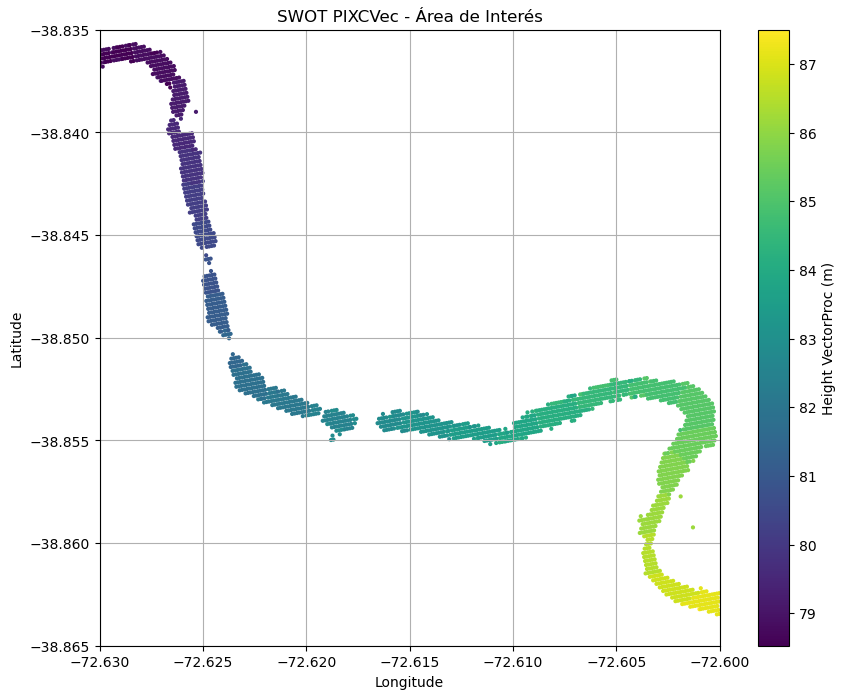


GeoPackage guardado en:
C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\PIXCVec\swot_pixcvec_2026_03_13.gpkg

Proceso finalizado correctamente.


In [113]:
import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

# ============================================================
# ARCHIVO SWOT PIXCVEC
# ============================================================

swot_id = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\PIXCVec\SWOT_L2_HR_PIXCVec_047_188_223L_20260313T170504_20260313T170515_PID0_01.nc'

# ============================================================
# ABRIR ARCHIVO
# ============================================================

nc = Dataset(swot_id)

print("Variables en raíz:")
print(nc.variables.keys())

# ============================================================
# LEER VARIABLES
# ============================================================

lat = np.array(nc.variables['latitude_vectorproc'][:])
lon = np.array(nc.variables['longitude_vectorproc'][:])
hgt = np.array(nc.variables['height_vectorproc'][:])

# node_id viene como matriz (N,14) de caracteres
node_id = np.array(nc.variables['node_id'][:])

# ============================================================
# CONVERTIR NODE_ID A STRING
# ============================================================

node_id_str = np.array([
    b''.join(fila).decode('utf-8').strip()
    for fila in node_id
])

print(f"\nTotal puntos: {len(node_id_str)}")
print(f"Con nodo: {np.sum(node_id_str != '')}")
print(f"Sin nodo: {np.sum(node_id_str == '')}")

# ============================================================
# DEFINICIÓN DE LÍMITES GEOGRÁFICOS
# ============================================================

lon_min, lon_max = -72.63, -72.60
lat_min, lat_max = -38.865, -38.835

# ============================================================
# FILTROS
# ============================================================

mask_finite = (
    np.isfinite(lat) &
    np.isfinite(lon) &
    np.isfinite(hgt)
)

mask_spatial = (
    (lon >= lon_min) &
    (lon <= lon_max) &
    (lat >= lat_min) &
    (lat <= lat_max)
)

# Mantener TODOS los píxeles (con y sin nodo)
mask_final = mask_finite & mask_spatial

# ============================================================
# APLICAR FILTROS
# ============================================================

lat_rec = lat[mask_final]
lon_rec = lon[mask_final]
hgt_rec = hgt[mask_final]
node_id_rec = node_id_str[mask_final]

print(f"\nPuntos dentro del área: {len(lat_rec)}")
print(f"Con nodo: {np.sum(node_id_rec != '')}")
print(f"Sin nodo: {np.sum(node_id_rec == '')}")

# ============================================================
# GRAFICAR
# ============================================================

plt.figure(figsize=(10, 8))

sc = plt.scatter(
    lon_rec,
    lat_rec,
    c=hgt_rec,
    s=4,
    cmap='viridis'
)

plt.colorbar(sc, label='Height VectorProc (m)')

plt.xlim(lon_min, lon_max)
plt.ylim(lat_min, lat_max)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('SWOT PIXCVec - Área de Interés')
plt.grid(True)

plt.show()

# ============================================================
# DATAFRAME FILTRADO
# ============================================================

df = pd.DataFrame({
    'longitude': lon_rec,
    'latitude': lat_rec,
    'node_id': node_id_rec,
    'height_vectorproc': hgt_rec
})

# ============================================================
# EXPORTAR CSV
# ============================================================

# ruta_csv = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\PIXCVec\swot_pixcvec_recortado.csv'

# df.to_csv(
#     ruta_csv,
#     sep=';',
#     decimal=',',
#     index=False,
#     encoding='utf-8-sig'
# )

# print(f"\nCSV guardado en:\n{ruta_csv}")

# ============================================================
# EXPORTAR GPKG
# ============================================================

geometry = [Point(xy) for xy in zip(df['longitude'], df['latitude'])]

gdf = gpd.GeoDataFrame(
    df,
    geometry=geometry,
    crs="EPSG:4326"
)

ruta_gpkg = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\PIXCVec\swot_pixcvec_2026_03_13.gpkg'

gdf.to_file(
    ruta_gpkg,
    layer='pixcvec_aoi',
    driver='GPKG'
)

print(f"\nGeoPackage guardado en:\n{ruta_gpkg}")

# ============================================================
# CERRAR ARCHIVO
# ============================================================

nc.close()

print("\nProceso finalizado correctamente.")

## PICX

In [ ]:
1 land 
2 land_near_water
3 water_near_land
4 open_water 
5 dark_water
6 low_coh_water_near_land 
7 open_low_coh_water

In [29]:
from netCDF4 import Dataset
import numpy as np
import matplotlib.pyplot as plt

# Ruta archivo SWOT PIXC
swot_id = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\PIXC\SWOT_L2_HR_PIXC_044_466_223R_20260120T011204_20260120T011215_PID0_01.nc'
#Dataset() de netCDF4 es la función/clase que abre o crea archivos NetCDF (.nc)
nc=Dataset(swot_id)

In [30]:
print(nc)

<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    Conventions: CF-1.7
    title: Level 2 KaRIn High Rate Water Mask Pixel Cloud Data Product
    institution: CNES
    source: Ka-band radar interferometer
    history: 2026-01-24T04:30:35Z : Creation
    platform: SWOT
    reference_document: D-56411_SWOT_Product_Description_L2_HR_PIXC
    contact: podaac@podaac.jpl.nasa.gov
    cycle_number: 44
    pass_number: 466
    tile_number: 223
    swath_side: R
    tile_name: 466_223R
    short_name: L2_HR_PIXC
    crid: PID0
    pge_name: PGE_L2_HR_PIXC
    pge_version: 5.4.2
    time_granule_start: 2026-01-20T01:12:04.458541Z
    time_granule_end: 2026-01-20T01:12:15.579799Z
    time_coverage_start: 2026-01-20T01:12:05.007383Z
    time_coverage_end: 2026-01-20T01:12:15.031320Z
    geospatial_lon_min: -72.8925436212217
    geospatial_lon_max: -71.91322811880377
    geospatial_lat_min: -39.46014413933396
    geospatial_lat_max: -38.69950133436532
    inner_first_l

In [96]:
#.groups.keys() muestra los nombres de los grupos
print("Grupos:")
print(nc.groups.keys())


# .variablel.keys() muestra los nombres de las variables, en este caso no hay variable en la raiz, pero si para cada grupo
print("\nVariables en raíz:")
print(nc.variables.keys())

print("\nVariables en 'pixel_cloud'") #el /n sirve como un espacio
#accedo al grupo pixel cloud con nc.groups['pixel_cloud'], para ver las variables, se usa .variable.keys()
print((nc.groups['pixel_cloud']).variables.keys())

print("\nVariables en 'noise'") #el /n sirve como un espacio
#accedo al grupo pixel cloud con nc.groups['pixel_cloud'], para ver las variables, se usa .variable.keys()
print((nc.groups['tvp']).variables.keys())

print("\nVariables en 'noise'") #el /n sirve como un espacio
#accedo al grupo pixel cloud con nc.groups['pixel_cloud'], para ver las variables, se usa .variable.keys()
print((nc.groups['noise']).variables.keys())


Grupos:
dict_keys(['pixel_cloud', 'tvp', 'noise'])

Variables en raíz:
dict_keys([])

Variables en 'pixel_cloud'
dict_keys(['azimuth_index', 'range_index', 'interferogram', 'power_plus_y', 'power_minus_y', 'coherent_power', 'x_factor_plus_y', 'x_factor_minus_y', 'water_frac', 'water_frac_uncert', 'classification', 'false_detection_rate', 'missed_detection_rate', 'prior_water_prob', 'prior_water_change', 'bright_land_flag', 'layover_impact', 'eff_num_rare_looks', 'latitude', 'longitude', 'height', 'cross_track', 'pixel_area', 'inc', 'phase_noise_std', 'dlatitude_dphase', 'dlongitude_dphase', 'dheight_dphase', 'dheight_droll', 'dheight_dbaseline', 'dheight_drange', 'darea_dheight', 'illumination_time', 'illumination_time_tai', 'eff_num_medium_looks', 'sig0', 'sig0_uncert', 'phase_unwrapping_region', 'ambiguity_cost1', 'ambiguity_cost2', 'instrument_range_cor', 'instrument_phase_cor', 'instrument_baseline_cor', 'sig0_cor_atmos_model', 'height_cor_xover', 'model_dry_tropo_cor', 'model_wet_

In [3]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [24]:
#se asignan el grupo a 'pixel_cloud' a la variable pixcloud y la varaible 'classificaction' a clas
pixcloud=nc.groups['pixel_cloud']
clas=pixcloud.variables['classification']

In [25]:
print(clas)
#aqui se ven los valores que puede tomar 'classification' que toma valores dependiendo del tipo de pixel, como agua, agua cerca de tierra, tierra, etc.


<class 'netCDF4.Variable'>
uint8 classification(points)
    _FillValue: 255
    long_name: classification
    quality_flag: classification_qual
    flag_meanings: land land_near_water water_near_land open_water dark_water low_coh_water_near_land open_low_coh_water
    flag_values: [1 2 3 4 5 6 7]
    valid_min: 1
    valid_max: 7
    coordinates: longitude latitude
    comment: Flags indicating water detection results.
path = /pixel_cloud
unlimited dimensions: 
current shape = (6037266,)
filling on


## _____________________________________________________
## BLOQUE: GRAFICAR PIXC FILTRADOS POR MÁSCARA RASTER

In [37]:
# ============================================================
# BLOQUE: GRAFICAR PIXC FILTRADOS POR CROSS_TRACK + MÁSCARA RASTER
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import rasterio
from rasterio.warp import transform

# ------------------------------------------------------------
# 1. ARCHIVOS DE ENTRADA
# ------------------------------------------------------------

PIXC_FILE = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\products\pixc\SWOT_L2_HR_PIXC_002_451_087L_20230827T042427_20230827T042438_PGD0_01.nc'

MASK_RASTER = r'C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif'

FILTRAR_POR_CROSS_TRACK = True
MIN_XTRACK_M = 10000
MAX_XTRACK_M = 60000

FILTRAR_POR_RASTER = True
MASK_VALUE = 2

# ------------------------------------------------------------
# 2. LEER PIXC
# ------------------------------------------------------------

nc = Dataset(PIXC_FILE)
pixc = nc.groups['pixel_cloud']

lat = np.array(pixc.variables['latitude'][:])
lon = np.array(pixc.variables['longitude'][:])
hgt = np.array(pixc.variables['height'][:])
cls = np.array(pixc.variables['classification'][:])
cross_track = np.array(pixc.variables['cross_track'][:])

nc.close()

# ------------------------------------------------------------
# 3. FILTRO BÁSICO DE VALORES VÁLIDOS
# ------------------------------------------------------------

mask_finite = (
    np.isfinite(lat) &
    np.isfinite(lon) &
    np.isfinite(hgt) &
    np.isfinite(cross_track)
)

lat_valid = lat[mask_finite]
lon_valid = lon[mask_finite]
hgt_valid = hgt[mask_finite]
cls_valid = cls[mask_finite]
cross_track_valid = cross_track[mask_finite]

print(f"Píxeles PIXC originales válidos: {len(lat_valid)}")

# ------------------------------------------------------------
# 4. FILTRO POR CROSS_TRACK
# ------------------------------------------------------------

if FILTRAR_POR_CROSS_TRACK:

    mask_cross_track = (
        (np.abs(cross_track_valid) >= MIN_XTRACK_M) &
        (np.abs(cross_track_valid) <= MAX_XTRACK_M)
    )

    lat_valid = lat_valid[mask_cross_track]
    lon_valid = lon_valid[mask_cross_track]
    hgt_valid = hgt_valid[mask_cross_track]
    cls_valid = cls_valid[mask_cross_track]
    cross_track_valid = cross_track_valid[mask_cross_track]

    print(
        f"Píxeles después de filtro cross_track "
        f"{MIN_XTRACK_M/1000:.0f}-{MAX_XTRACK_M/1000:.0f} km: "
        f"{len(lat_valid)}"
    )

else:
    print("Filtro cross_track desactivado.")

# ------------------------------------------------------------
# 5. LEER RASTER MÁSCARA
# ------------------------------------------------------------

with rasterio.open(MASK_RASTER) as src:

    raster_crs = src.crs
    nodata = src.nodata
    bounds = src.bounds
    raster_img = src.read(1)

    print(f"CRS raster: {raster_crs}")
    print(f"Resolución: {src.res}")
    print(f"Valor NoData: {nodata}")
    print(f"Extensión raster: {bounds}")

    # --------------------------------------------------------
    # 6. TRANSFORMAR COORDENADAS PIXC AL CRS DEL RASTER
    # --------------------------------------------------------

    if raster_crs.to_string() != 'EPSG:4326':

        x, y = transform(
            'EPSG:4326',
            raster_crs,
            lon_valid.tolist(),
            lat_valid.tolist()
        )

        x = np.array(x)
        y = np.array(y)

    else:
        x = lon_valid.copy()
        y = lat_valid.copy()

    # --------------------------------------------------------
    # 7. FILTRAR PIXC POR EXTENSIÓN DEL RASTER
    # --------------------------------------------------------

    mask_extent = (
        (x >= bounds.left) &
        (x <= bounds.right) &
        (y >= bounds.bottom) &
        (y <= bounds.top)
    )

    x_ext = x[mask_extent]
    y_ext = y[mask_extent]

    lon_ext = lon_valid[mask_extent]
    lat_ext = lat_valid[mask_extent]
    hgt_ext = hgt_valid[mask_extent]
    cls_ext = cls_valid[mask_extent]
    cross_track_ext = cross_track_valid[mask_extent]

    print(f"Píxeles PIXC dentro de la extensión raster: {len(lon_ext)}")

    # --------------------------------------------------------
    # 8. FILTRO OPCIONAL POR CLASE DEL RASTER
    # --------------------------------------------------------

    if FILTRAR_POR_RASTER:

        coords = list(zip(x_ext, y_ext))

        raster_values = np.array([
            value[0]
            for value in src.sample(coords)
        ])

        mask_raster = raster_values == MASK_VALUE

        x_rec = x_ext[mask_raster]
        y_rec = y_ext[mask_raster]
        lon_rec = lon_ext[mask_raster]
        lat_rec = lat_ext[mask_raster]
        hgt_rec = hgt_ext[mask_raster]
        cls_rec = cls_ext[mask_raster]
        cross_track_rec = cross_track_ext[mask_raster]

        print(
            f"Píxeles después de filtrar clase raster "
            f"{MASK_VALUE}: {len(lon_rec)}"
        )

    else:

        x_rec = x_ext
        y_rec = y_ext
        lon_rec = lon_ext
        lat_rec = lat_ext
        hgt_rec = hgt_ext
        cls_rec = cls_ext
        cross_track_rec = cross_track_ext

        print(
            f"Filtro por máscara desactivado. "
            f"Se conservan {len(lon_rec)} píxeles dentro de la extensión."
        )

# ------------------------------------------------------------
# 9. RESUMEN FINAL CROSS_TRACK
# ------------------------------------------------------------

if len(cross_track_rec) > 0:

    print("\n===== RESUMEN CROSS_TRACK FINAL =====")
    print(f"Cross-track mínimo: {np.min(cross_track_rec):.1f} m")
    print(f"Cross-track máximo: {np.max(cross_track_rec):.1f} m")
    print(f"Cross-track promedio: {np.mean(cross_track_rec):.1f} m")
    print(
        f"|Cross-track| promedio: "
        f"{np.mean(np.abs(cross_track_rec)):.1f} m"
    )

# ------------------------------------------------------------
# 10. GRAFICAR RASTER + PIXELES PIXC
# ------------------------------------------------------------

if len(x_rec) > 0:

    plt.figure(figsize=(10, 8))

    plt.imshow(
        raster_img,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top
        ],
        origin='upper',
        cmap='gray',
        alpha=0.5
    )

    sc = plt.scatter(
        x_rec,
        y_rec,
        c=hgt_rec,
        s=4,
        cmap='viridis'
    )

    plt.colorbar(sc, label='Height (m)')

    plt.xlabel('X')
    plt.ylabel('Y')

    titulo = (
        f'SWOT PIXC + raster\n'
        f'|cross_track| = '
        f'{MIN_XTRACK_M/1000:.0f}-{MAX_XTRACK_M/1000:.0f} km'
    )

    if FILTRAR_POR_RASTER:
        titulo += f' + clase raster = {MASK_VALUE}'
    else:
        titulo += ' + solo extensión raster'

    plt.title(titulo)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("No se encontraron píxeles PIXC para graficar.")


Píxeles PIXC originales válidos: 6240915
Píxeles después de filtro cross_track 10-60 km: 5420014
CRS raster: EPSG:32718
Resolución: (10.0, 10.0)
Valor NoData: 0.0
Extensión raster: BoundingBox(left=716040.0, bottom=5714290.0, right=719040.0, top=5716200.0)
Píxeles PIXC dentro de la extensión raster: 276
Píxeles después de filtrar clase raster 2: 1

===== RESUMEN CROSS_TRACK FINAL =====
Cross-track mínimo: -10187.6 m
Cross-track máximo: -10187.6 m
Cross-track promedio: -10187.6 m
|Cross-track| promedio: 10187.6 m


In [38]:
%matplotlib qt

In [39]:
# ------------------------------------------------------------
# 8. GRAFICAR PIXELES PIXC FILTRADOS EN 3D
# ------------------------------------------------------------

if len(lon_rec) > 0:

    fig = plt.figure(figsize=(12, 9))

    ax = fig.add_subplot(
        111,
        projection='3d'
    )

    sc = ax.scatter(
        lon_rec,
        lat_rec,
        hgt_rec,
        c=hgt_rec,
        cmap='viridis',
        s=19,
        alpha=0.8
    )

    # Barra de colores
    cbar = fig.colorbar(
        sc,
        ax=ax,
        shrink=0.7,
        pad=0.1
    )

    cbar.set_label('Height (m)')

    # Etiquetas
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_zlabel('Height (m)')

    ax.set_title(
        f'SWOT PIXC filtrado por máscara raster\n'
        f'Clase raster = {MASK_VALUE}'
    )

    # --------------------------------------------------------
    # CONTROL DE LA PERSPECTIVA
    # --------------------------------------------------------

    # Ángulo de cámara
    ax.view_init(
        elev=30,     # altura de la cámara
        azim=-90     # rotación horizontal
    )

    # Proporción visual de los ejes
    # El tercer valor controla cuánto se exagera/comprime Z
    ax.set_box_aspect((1, 1, 1))

    # --------------------------------------------------------

    plt.tight_layout()
    plt.show()

else:

    print(
        f"No se encontraron píxeles PIXC "
        f"sobre la clase raster {MASK_VALUE}."
    )

Píxeles PIXC con coordenadas y clase válidas: 5642086
CRS raster: EPSG:32718
Resolución: (10.0, 10.0)
Valor NoData: 0.0
Extensión raster: BoundingBox(left=705610.0, bottom=5695540.0, right=708860.0, top=5698860.0)
Píxeles PIXC dentro de la extensión raster: 13041
Filtro por máscara desactivado. Se conservan 13041 píxeles dentro de la extensión.

Clases PIXC presentes:
[1 2 3 4 5 6 7]
Clase 1: 9722 píxeles
Clase 2: 1679 píxeles
Clase 3: 976 píxeles
Clase 4: 154 píxeles
Clase 5: 75 píxeles
Clase 6: 405 píxeles
Clase 7: 30 píxeles


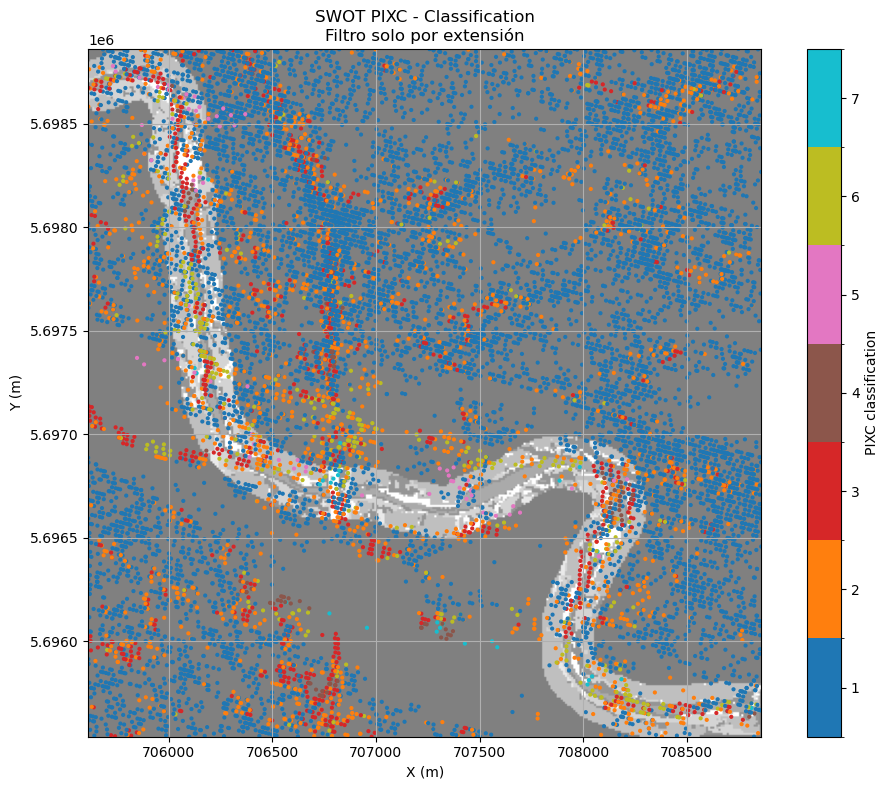

In [11]:
# ============================================================
# BLOQUE: GRAFICAR CLASES PIXC FILTRADAS POR MÁSCARA RASTER
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from netCDF4 import Dataset
import rasterio
from rasterio.warp import transform

# ------------------------------------------------------------
# 1. ARCHIVOS DE ENTRADA
# ------------------------------------------------------------

# Archivo SWOT PIXC individual
PIXC_FILE = r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\products\pixc\SWOT_L2_HR_PIXC_049_451_086L_20260503T194301_20260503T194312_PID0_01.nc'

# Raster máscara correspondiente
MASK_RASTER = r'C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\NMF_S1_S2_ABR_MAY_2018_2025_NMF_CLASE.tif'

# Aplicar o no el filtro por clase raster
FILTRAR_POR_RASTER = False

# Valor del raster que queremos conservar
# Por ejemplo: 2 = río
MASK_VALUE = 2


# ------------------------------------------------------------
# 2. LEER PIXC
# ------------------------------------------------------------

nc = Dataset(PIXC_FILE)

pixc = nc.groups['pixel_cloud']

lat = np.array(pixc.variables['latitude'][:])
lon = np.array(pixc.variables['longitude'][:])
hgt = np.array(pixc.variables['height'][:])
cls = np.array(pixc.variables['classification'][:])

nc.close()


# ------------------------------------------------------------
# 3. FILTRO BÁSICO PARA GRAFICAR CLASSIFICATION
# ------------------------------------------------------------

mask_finite = (
    np.isfinite(lat) &
    np.isfinite(lon) &
    np.isfinite(cls)
)

lat_valid = lat[mask_finite]
lon_valid = lon[mask_finite]
cls_valid = cls[mask_finite]

# Height se conserva, pero NO participa en el filtro
hgt_valid = hgt[mask_finite]

print(f"Píxeles PIXC con coordenadas y clase válidas: {len(lat_valid)}")


# ------------------------------------------------------------
# 4. LEER RASTER MÁSCARA
# ------------------------------------------------------------

with rasterio.open(MASK_RASTER) as src:

    raster_crs = src.crs
    nodata = src.nodata
    bounds = src.bounds
    raster_img = src.read(1)

    print(f"CRS raster: {raster_crs}")
    print(f"Resolución: {src.res}")
    print(f"Valor NoData: {nodata}")
    print(f"Extensión raster: {bounds}")


    # --------------------------------------------------------
    # 5. TRANSFORMAR COORDENADAS PIXC AL CRS DEL RASTER
    # --------------------------------------------------------

    if raster_crs.to_string() != 'EPSG:4326':

        x, y = transform(
            'EPSG:4326',
            raster_crs,
            lon_valid.tolist(),
            lat_valid.tolist()
        )

        x = np.array(x)
        y = np.array(y)

    else:

        x = lon_valid.copy()
        y = lat_valid.copy()


    # --------------------------------------------------------
    # 6. FILTRAR PIXC POR EXTENSIÓN DEL RASTER
    # --------------------------------------------------------

    mask_extent = (
        (x >= bounds.left) &
        (x <= bounds.right) &
        (y >= bounds.bottom) &
        (y <= bounds.top)
    )

    x_ext = x[mask_extent]
    y_ext = y[mask_extent]

    lon_ext = lon_valid[mask_extent]
    lat_ext = lat_valid[mask_extent]
    hgt_ext = hgt_valid[mask_extent]
    cls_ext = cls_valid[mask_extent]

    print(
        f"Píxeles PIXC dentro de la extensión raster: "
        f"{len(lon_ext)}"
    )


    # --------------------------------------------------------
    # 7. FILTRO OPCIONAL POR CLASE DEL RASTER
    # --------------------------------------------------------

    if FILTRAR_POR_RASTER:

        coords = list(zip(x_ext, y_ext))

        raster_values = np.array([
            value[0]
            for value in src.sample(coords)
        ])

        mask_raster = raster_values == MASK_VALUE

        x_rec = x_ext[mask_raster]
        y_rec = y_ext[mask_raster]

        lon_rec = lon_ext[mask_raster]
        lat_rec = lat_ext[mask_raster]
        hgt_rec = hgt_ext[mask_raster]
        cls_rec = cls_ext[mask_raster]

        print(
            f"Píxeles después de filtrar clase raster "
            f"{MASK_VALUE}: {len(lon_rec)}"
        )

    else:

        x_rec = x_ext
        y_rec = y_ext

        lon_rec = lon_ext
        lat_rec = lat_ext
        hgt_rec = hgt_ext
        cls_rec = cls_ext

        print(
            f"Filtro por máscara desactivado. "
            f"Se conservan {len(lon_rec)} píxeles "
            f"dentro de la extensión."
        )


# ------------------------------------------------------------
# 8. MOSTRAR CLASES PIXC PRESENTES
# ------------------------------------------------------------

clases_presentes = np.unique(cls_rec).astype(int)

print("\nClases PIXC presentes:")
print(clases_presentes)

for clase in clases_presentes:

    n = np.sum(cls_rec == clase)

    print(
        f"Clase {clase}: "
        f"{n} píxeles"
    )


# ------------------------------------------------------------
# 9. GRAFICAR RASTER + CLASES PIXC
# ------------------------------------------------------------

if len(x_rec) > 0:

    plt.figure(figsize=(10, 8))

    # --------------------------------------------------------
    # Raster de fondo
    # --------------------------------------------------------

    plt.imshow(
        raster_img,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top
        ],
        origin='upper',
        cmap='gray',
        alpha=0.5
    )


    # --------------------------------------------------------
    # Crear colores discretos para las clases PIXC
    # --------------------------------------------------------

    clase_min = int(np.min(cls_rec))
    clase_max = int(np.max(cls_rec))

    boundaries = np.arange(
        clase_min - 0.5,
        clase_max + 1.5,
        1
    )

    cmap = plt.get_cmap(
        'tab10',
        clase_max - clase_min + 1
    )

    norm = BoundaryNorm(
        boundaries,
        cmap.N
    )


    # --------------------------------------------------------
    # PIXC coloreados según CLASSIFICATION
    # --------------------------------------------------------

    sc = plt.scatter(
        x_rec,
        y_rec,
        c=cls_rec,
        s=4,
        cmap=cmap,
        norm=norm
    )


    # --------------------------------------------------------
    # Barra de colores
    # --------------------------------------------------------

    cbar = plt.colorbar(
        sc,
        ticks=clases_presentes
    )

    cbar.set_label('PIXC classification')


    # --------------------------------------------------------
    # Ejes
    # --------------------------------------------------------

    plt.xlabel('X (m)')
    plt.ylabel('Y (m)')


    # --------------------------------------------------------
    # Título
    # --------------------------------------------------------

    if FILTRAR_POR_RASTER:

        titulo = (
            'SWOT PIXC - Classification\n'
            f'Extensión + clase raster = {MASK_VALUE}'
        )

    else:

        titulo = (
            'SWOT PIXC - Classification\n'
            'Filtro solo por extensión'
        )

    plt.title(titulo)

    plt.grid(True)

    plt.tight_layout()
    plt.show()


else:

    print("No se encontraron píxeles PIXC para graficar.")

In [7]:
# ------------------------------------------------------------
# 9. BOXPLOT DE ALTURA DE LOS PIXELES FILTRADOS
# ------------------------------------------------------------

if len(hgt_rec) > 0:

    plt.figure(figsize=(6, 8))

    plt.boxplot(
        hgt_rec,
        vert=True,
        showfliers=True
    )

    plt.ylabel('Height (m)')
    plt.title(
        f'Distribución de altura de píxeles SWOT PIXC\n'
        f'Máscara raster = {MASK_VALUE}'
    )

    plt.xticks([1], ['PIXC'])
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

Total de píxeles válidos: 2,608,527

===== DISTRIBUCIÓN DE CLASES PIXC =====
1 | Land                         | 2,040,640 píxeles |  78.23%
2 | land_near_water              |  213,444 píxeles |   8.18%
3 | water_near_land              |   68,081 píxeles |   2.61%
4 | open_water                   |   23,879 píxeles |   0.92%
5 | dark_water                   |   47,098 píxeles |   1.81%
6 | low_coh_water_near_land      |  118,558 píxeles |   4.55%
7 | open_low_coh_water           |   96,827 píxeles |   3.71%
Clase 1: 2,040,640 originales → 15,000 representados
Clase 2: 213,444 originales → 15,000 representados
Clase 3: 68,081 originales → 15,000 representados
Clase 4: 23,879 originales → 15,000 representados
Clase 5: 47,098 originales → 15,000 representados
Clase 6: 118,558 originales → 15,000 representados
Clase 7: 96,827 originales → 15,000 representados

TOTAL REPRESENTADO: 105,000 píxeles


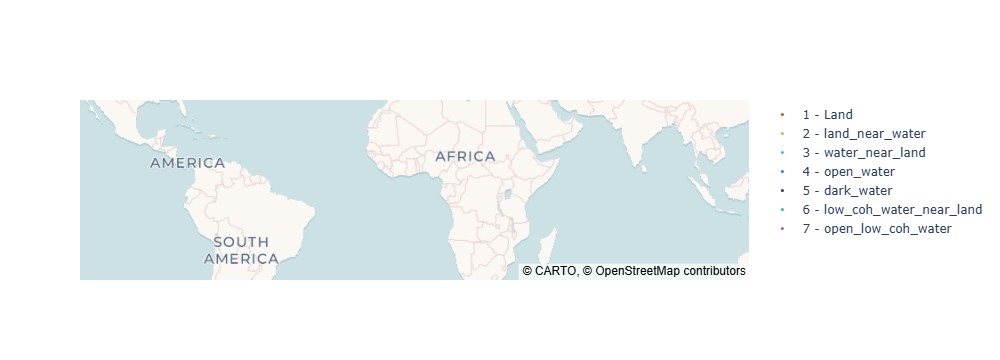

In [5]:

# ============================================================
# SWOT PIXC - VISUALIZACIÓN 2D INTERACTIVA POR CLASIFICACIÓN
# Plotly | Sin raster | Sin máscara externa
# ============================================================

import numpy as np
import plotly.graph_objects as go
from netCDF4 import Dataset

# ============================================================
# OPTIMIZACIÓN DE MEMORIA
# ============================================================

# Máximo de píxeles representados por clase
MAX_PIXELES_POR_CLASE = 15000

# Semilla para que el muestreo sea reproducible
SEMILLA = 42

# Tamaño de puntos
TAMANO_PUNTO = 3

# Opacidad
OPACIDAD = 0.8

# ------------------------------------------------------------
# 1. ARCHIVO PIXC
# ------------------------------------------------------------

PIXC_FILE = (
    r'C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\PIXC\SWOT_L2_HR_PIXC_001_451_087R_20230806T073922_20230806T073933_PGD0_01.nc'
)

# ------------------------------------------------------------
# 2. CLASES PIXC Y COLORES
# ------------------------------------------------------------

NOMBRES_CLASES = {
    1: "Land",
    2: "land_near_water",
    3: "water_near_land",
    4: "open_water",
    5: "dark_water",
    6: "low_coh_water_near_land",
    7: "open_low_coh_water"
}

COLORES_CLASES = {
    1: "#8B4513",  # Marrón
    2: "#DAA520",  # Dorado
    3: "#00BFFF",  # Celeste
    4: "#0066FF",  # Azul
    5: "#001B44",  # Azul muy oscuro
    6: "#00B894",  # Verde turquesa
    7: "#8E44AD"   # Morado
}

TAMANO_PUNTO = 3
OPACIDAD = 0.85

# ------------------------------------------------------------
# 3. LEER PIXC
# ------------------------------------------------------------

with Dataset(PIXC_FILE) as nc:

    pixc = nc.groups["pixel_cloud"]

    lat = np.ma.filled(
        pixc.variables["latitude"][:].astype(float),
        np.nan
    )

    lon = np.ma.filled(
        pixc.variables["longitude"][:].astype(float),
        np.nan
    )

    cls = np.ma.filled(
        pixc.variables["classification"][:].astype(float),
        np.nan
    )

# ------------------------------------------------------------
# 4. VALIDAR COORDENADAS Y CLASIFICACIONES
# ------------------------------------------------------------

mask_valid = (
    np.isfinite(lat) &
    np.isfinite(lon) &
    np.isfinite(cls) &
    np.isin(cls, list(NOMBRES_CLASES.keys()))
)

lat = lat[mask_valid]
lon = lon[mask_valid]
cls = cls[mask_valid].astype(int)

print(f"Total de píxeles válidos: {len(cls):,}")

# ------------------------------------------------------------
# 5. RESUMEN DE CLASES
# ------------------------------------------------------------

print("\n===== DISTRIBUCIÓN DE CLASES PIXC =====")

for clase, nombre in NOMBRES_CLASES.items():

    cantidad = np.sum(cls == clase)

    porcentaje = (
        100 * cantidad / len(cls)
        if len(cls) > 0 else 0
    )

    print(
        f"{clase} | {nombre:28s} | "
        f"{cantidad:8,d} píxeles | {porcentaje:6.2f}%"
    )

# ------------------------------------------------------------
# 6. CREAR FIGURA INTERACTIVA
# ------------------------------------------------------------

fig = go.Figure()

for clase, nombre in NOMBRES_CLASES.items():

    mask_clase = cls == clase

    if not np.any(mask_clase):
        continue

    fig.add_trace(

        go.Scattergl(
            x=lon[mask_clase],
            y=lat[mask_clase],

            mode="markers",

            name=f"{clase} - {nombre}",

            marker=dict(
                size=TAMANO_PUNTO,
                color=COLORES_CLASES[clase],
                opacity=OPACIDAD
            ),

            customdata=np.full(
                np.sum(mask_clase),
                clase
            ),

            hovertemplate=(
                "Clase: %{customdata}<br>"
                "Longitud: %{x:.6f}<br>"
                "Latitud: %{y:.6f}"
                "<extra></extra>"
            )
        )
    )


# ============================================================
# 7. CREAR FIGURA OPTIMIZADA EN MEMORIA
# ============================================================

rng = np.random.default_rng(SEMILLA)

fig = go.Figure()

total_representados = 0

for clase, nombre in NOMBRES_CLASES.items():

    # Índices de los píxeles correspondientes a esta clase
    indices = np.flatnonzero(cls == clase)

    n_original = len(indices)

    if n_original == 0:
        continue

    # Muestreo aleatorio cuando supera el límite
    if n_original > MAX_PIXELES_POR_CLASE:

        indices = rng.choice(
            indices,
            size=MAX_PIXELES_POR_CLASE,
            replace=False
        )

    n_muestra = len(indices)
    total_representados += n_muestra

    # Coordenadas en float32
    lat_clase = lat[indices].astype(np.float32)
    lon_clase = lon[indices].astype(np.float32)

    fig.add_trace(

        go.Scattermap(

            lat=lat_clase,
            lon=lon_clase,

            mode="markers",

            name=f"{clase} - {nombre}",

            marker=dict(
                size=TAMANO_PUNTO,
                color=COLORES_CLASES[clase],
                opacity=OPACIDAD
            ),

            hovertemplate=(
                f"<b>{nombre}</b><br>"
                f"Clase: {clase}<br>"
                "Longitud: %{lon:.6f}<br>"
                "Latitud: %{lat:.6f}"
                "<extra></extra>"
            )
        )
    )

    print(
        f"Clase {clase}: "
        f"{n_original:,} originales → "
        f"{n_muestra:,} representados"
    )

print(
    f"\nTOTAL REPRESENTADO: "
    f"{total_representados:,} píxeles"
)


# ------------------------------------------------------------
# 8. HERRAMIENTAS INTERACTIVAS
# ------------------------------------------------------------

fig.show(
    config={
        "scrollZoom": True,
        "displayModeBar": True,
        "displaylogo": False,
        "toImageButtonOptions": {
            "format": "png",
            "filename": "SWOT_PIXC_classification",
            "height": 1000,
            "width": 1400,
            "scale": 2
        }
    }
)


# Recortar archivs .nc a extensión de raster

In [4]:
from pathlib import Path

import numpy as np
import rasterio
from rasterio.warp import transform_bounds
from netCDF4 import Dataset


# ============================================================
# CONFIGURACIÓN
# ============================================================

CARPETA_NC = Path(r"C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\products\pixc")
RASTER_MASCARA = Path(r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida quepe en quepe\NMF_S1_S2_ABR_MAY_2018_2025_NMF_CLASE.tif")
CARPETA_SALIDA = Path(r"D:\archivos pixc recortados\Quepe en Quepe")

# Nombres habituales en productos SWOT
NOMBRE_LATITUD = "latitude"
NOMBRE_LONGITUD = "longitude"

# True = reemplaza archivos existentes
SOBRESCRIBIR = True


# ============================================================
# EXTENSIÓN DEL RASTER
# ============================================================

def obtener_extension_raster_wgs84(raster_path):
    """
    Obtiene la extensión del raster y la transforma a EPSG:4326.
    No utiliza los valores del raster, solamente su bounding box.
    """

    with rasterio.open(raster_path) as src:

        if src.crs is None:
            raise ValueError(
                f"El raster no tiene CRS definido: {raster_path}"
            )

        bounds = src.bounds

        # Transformamos solamente la extensión a WGS84
        if src.crs.to_epsg() == 4326:
            west, south, east, north = (
                bounds.left,
                bounds.bottom,
                bounds.right,
                bounds.top,
            )
        else:
            west, south, east, north = transform_bounds(
                src.crs,
                "EPSG:4326",
                bounds.left,
                bounds.bottom,
                bounds.right,
                bounds.top,
                densify_pts=21,
            )

    return west, south, east, north


# ============================================================
# BUSCAR LATITUD Y LONGITUD
# ============================================================

def buscar_grupo_lat_lon(grupo):
    """
    Busca recursivamente un grupo que contenga las variables
    latitude y longitude.
    """

    if (
        NOMBRE_LATITUD in grupo.variables
        and NOMBRE_LONGITUD in grupo.variables
    ):
        return grupo

    for subgrupo in grupo.groups.values():
        resultado = buscar_grupo_lat_lon(subgrupo)

        if resultado is not None:
            return resultado

    return None


# ============================================================
# COPIAR ATRIBUTOS
# ============================================================

def copiar_atributos(origen, destino, excluir=None):

    if excluir is None:
        excluir = []

    for atributo in origen.ncattrs():

        if atributo in excluir:
            continue

        try:
            destino.setncattr(
                atributo,
                origen.getncattr(atributo)
            )
        except Exception:
            pass


# ============================================================
# OBTENER DIMENSIÓN ESPACIAL
# ============================================================

def obtener_dimension_pixeles(lat_var, lon_var):
    """
    Para productos tipo PIXC, latitude y longitude normalmente
    dependen de una dimensión común, por ejemplo:
        points
        num_pixc_lines
        etc.

    Esta función identifica esa dimensión.
    """

    dimensiones_comunes = [
        d for d in lat_var.dimensions
        if d in lon_var.dimensions
    ]

    if len(dimensiones_comunes) == 0:
        raise ValueError(
            "Latitude y longitude no tienen una dimensión común."
        )

    # Para PIXC normalmente existe una sola
    if len(lat_var.dimensions) == 1:
        return lat_var.dimensions[0]

    # Si existen varias, utilizamos la última dimensión común
    return dimensiones_comunes[-1]


# ============================================================
# CREAR VARIABLE CONSERVANDO PROPIEDADES
# ============================================================

def crear_variable(destino, variable_origen):

    nombre = variable_origen.name

    fill_value = None

    if "_FillValue" in variable_origen.ncattrs():
        fill_value = variable_origen.getncattr("_FillValue")

    kwargs = {}

    # Intentamos conservar compresión
    try:
        filtros = variable_origen.filters()

        if filtros:

            if filtros.get("zlib"):
                kwargs["zlib"] = True

            if filtros.get("complevel") is not None:
                kwargs["complevel"] = filtros["complevel"]

            if filtros.get("shuffle") is not None:
                kwargs["shuffle"] = filtros["shuffle"]

            if filtros.get("fletcher32"):
                kwargs["fletcher32"] = True

    except Exception:
        pass

    if fill_value is not None:
        kwargs["fill_value"] = fill_value

    try:
        variable_destino = destino.createVariable(
            nombre,
            variable_origen.datatype,
            variable_origen.dimensions,
            **kwargs,
        )

    except Exception:
        # Si alguna configuración especial de compresión
        # genera problemas, se crea conservando datatype y fill value.

        kwargs_simple = {}

        if fill_value is not None:
            kwargs_simple["fill_value"] = fill_value

        variable_destino = destino.createVariable(
            nombre,
            variable_origen.datatype,
            variable_origen.dimensions,
            **kwargs_simple,
        )

    copiar_atributos(
        variable_origen,
        variable_destino,
        excluir=["_FillValue"],
    )

    return variable_destino


# ============================================================
# COPIAR GRUPO RECURSIVAMENTE
# ============================================================

def copiar_grupo(
    grupo_origen,
    grupo_destino,
    dimension_recorte,
    indices,
):
    """
    Copia recursivamente grupos, dimensiones y variables.

    Las variables que utilizan dimension_recorte son filtradas
    usando indices.

    Las demás variables se copian completas.
    """

    # --------------------------------------------------------
    # ATRIBUTOS DEL GRUPO
    # --------------------------------------------------------

    copiar_atributos(grupo_origen, grupo_destino)

    # --------------------------------------------------------
    # DIMENSIONES LOCALES
    # --------------------------------------------------------

    for nombre_dim, dimension in grupo_origen.dimensions.items():

        if nombre_dim in grupo_destino.dimensions:
            continue

        if nombre_dim == dimension_recorte:

            grupo_destino.createDimension(
                nombre_dim,
                len(indices)
            )

        else:

            if dimension.isunlimited():
                grupo_destino.createDimension(
                    nombre_dim,
                    None
                )
            else:
                grupo_destino.createDimension(
                    nombre_dim,
                    len(dimension)
                )

    # --------------------------------------------------------
    # VARIABLES
    # --------------------------------------------------------

    for nombre_var, var_origen in grupo_origen.variables.items():

        var_destino = crear_variable(
            grupo_destino,
            var_origen,
        )

        # Variable escalar
        if len(var_origen.dimensions) == 0:

            try:
                var_destino.assignValue(
                    var_origen.getValue()
                )
            except Exception:
                var_destino[...] = var_origen[...]

            continue

        # ----------------------------------------------------
        # Variable dependiente de dimensión espacial
        # ----------------------------------------------------

        if dimension_recorte in var_origen.dimensions:

            eje = var_origen.dimensions.index(
                dimension_recorte
            )

            datos = var_origen[...]

            datos_recortados = np.take(
                datos,
                indices,
                axis=eje,
            )

            var_destino[...] = datos_recortados

        # ----------------------------------------------------
        # Variable independiente del recorte
        # ----------------------------------------------------

        else:

            var_destino[...] = var_origen[...]

    # --------------------------------------------------------
    # SUBGRUPOS
    # --------------------------------------------------------

    for nombre_subgrupo, subgrupo_origen in grupo_origen.groups.items():

        subgrupo_destino = grupo_destino.createGroup(
            nombre_subgrupo
        )

        copiar_grupo(
            subgrupo_origen,
            subgrupo_destino,
            dimension_recorte,
            indices,
        )


# ============================================================
# PROCESAR UN NETCDF
# ============================================================

def procesar_netcdf(
    archivo_nc,
    archivo_salida,
    bbox,
):

    west, south, east, north = bbox

    print()
    print("=" * 80)
    print(f"Analizando: {archivo_nc.name}")

    with Dataset(archivo_nc, "r") as ds:

        # ----------------------------------------------------
        # BUSCAR GRUPO CON LAT/LON
        # ----------------------------------------------------

        grupo_geo = buscar_grupo_lat_lon(ds)

        if grupo_geo is None:

            print("  ⚠ No se encontraron latitude/longitude.")
            print("  → Archivo ignorado.")

            return False

        lat_var = grupo_geo.variables[NOMBRE_LATITUD]
        lon_var = grupo_geo.variables[NOMBRE_LONGITUD]

        lat = np.asarray(lat_var[:])
        lon = np.asarray(lon_var[:])

        # Eliminar máscaras de numpy si existen
        if np.ma.isMaskedArray(lat):
            lat = lat.filled(np.nan)

        if np.ma.isMaskedArray(lon):
            lon = lon.filled(np.nan)

        # ----------------------------------------------------
        # EXTENSIÓN DEL NETCDF
        # ----------------------------------------------------

        validos = (
            np.isfinite(lat)
            & np.isfinite(lon)
        )

        if not np.any(validos):

            print("  ⚠ No existen coordenadas válidas.")
            return False

        min_lat = np.nanmin(lat[validos])
        max_lat = np.nanmax(lat[validos])

        min_lon = np.nanmin(lon[validos])
        max_lon = np.nanmax(lon[validos])

        print(
            f"  NC: "
            f"Lon [{min_lon:.5f}, {max_lon:.5f}]  "
            f"Lat [{min_lat:.5f}, {max_lat:.5f}]"
        )

        # ----------------------------------------------------
        # COMPROBAR INTERSECCIÓN DE EXTENSIONES
        # ----------------------------------------------------

        intersecta = not (
            max_lon < west
            or min_lon > east
            or max_lat < south
            or min_lat > north
        )

        if not intersecta:

            print("  ✖ No intersecta extensión del raster.")
            print("  → Archivo ignorado.")

            return False

        # ----------------------------------------------------
        # MÁSCARA ESPACIAL
        # ----------------------------------------------------

        mascara = (
            validos
            & (lon >= west)
            & (lon <= east)
            & (lat >= south)
            & (lat <= north)
        )

        # Este script está pensado para coordenadas 1D
        if mascara.ndim != 1:

            raise ValueError(
                f"{archivo_nc.name}: latitude/longitude no son 1D. "
                "El archivo parece utilizar una grilla multidimensional."
            )

        indices = np.where(mascara)[0]

        if len(indices) == 0:

            print("  ✖ Intersecta bounding box, pero no contiene píxeles.")
            print("  → Archivo ignorado.")

            return False

        print(
            f"  ✔ Píxeles originales : {lat.size:,}"
        )

        print(
            f"  ✔ Píxeles conservados: {len(indices):,}"
        )

        # ----------------------------------------------------
        # IDENTIFICAR DIMENSIÓN A RECORTAR
        # ----------------------------------------------------

        dimension_recorte = obtener_dimension_pixeles(
            lat_var,
            lon_var
        )

        print(
            f"  ✔ Dimensión recortada: {dimension_recorte}"
        )

        # ----------------------------------------------------
        # CREAR ARCHIVO NUEVO
        # ----------------------------------------------------

        formato = ds.file_format

        with Dataset(
            archivo_salida,
            "w",
            format=formato,
        ) as dst:

            copiar_grupo(
                ds,
                dst,
                dimension_recorte,
                indices,
            )

    print(f"  ✔ Guardado: {archivo_salida}")

    return True


# ============================================================
# MAIN
# ============================================================

def main():

    CARPETA_SALIDA.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # EXTENSIÓN DEL RASTER
    # --------------------------------------------------------

    bbox = obtener_extension_raster_wgs84(
        RASTER_MASCARA
    )

    west, south, east, north = bbox

    print("=" * 80)
    print("EXTENSIÓN DEL RASTER EN EPSG:4326")
    print("=" * 80)

    print(f"Oeste : {west:.6f}")
    print(f"Este  : {east:.6f}")
    print(f"Sur   : {south:.6f}")
    print(f"Norte : {north:.6f}")

    # --------------------------------------------------------
    # ARCHIVOS NC
    # --------------------------------------------------------

    archivos_nc = sorted(
        CARPETA_NC.glob("*.nc")
    )

    print()
    print(f"Archivos .nc encontrados: {len(archivos_nc)}")

    procesados = 0
    ignorados = 0
    errores = 0

    # --------------------------------------------------------
    # PROCESAR TODOS
    # --------------------------------------------------------

    for archivo_nc in archivos_nc:

        archivo_salida = (
            CARPETA_SALIDA
            / archivo_nc.name
        )

        if archivo_salida.exists():

            if SOBRESCRIBIR:
                archivo_salida.unlink()
            else:
                print(
                    f"Ya existe: {archivo_salida.name}. "
                    "Se omite."
                )
                continue

        try:

            resultado = procesar_netcdf(
                archivo_nc,
                archivo_salida,
                bbox,
            )

            if resultado:
                procesados += 1
            else:
                ignorados += 1

        except Exception as e:

            errores += 1

            print()
            print(
                f"  ❌ ERROR en {archivo_nc.name}:"
            )
            print(f"     {e}")

            # Borrar archivo incompleto
            if archivo_salida.exists():
                archivo_salida.unlink()

    # --------------------------------------------------------
    # RESUMEN
    # --------------------------------------------------------

    print()
    print("=" * 80)
    print("PROCESO FINALIZADO")
    print("=" * 80)

    print(f"Total encontrados : {len(archivos_nc)}")
    print(f"Recortados        : {procesados}")
    print(f"Ignorados         : {ignorados}")
    print(f"Errores            : {errores}")

    print()
    print(f"Salida: {CARPETA_SALIDA}")


if __name__ == "__main__":
    main()

EXTENSIÓN DEL RASTER EN EPSG:4326
Oeste : -72.631160
Este  : -72.592739
Sur   : -38.864958
Norte : -38.834300

Archivos .nc encontrados: 341

Analizando: SWOT_L2_HR_PIXC_001_188_222L_20230727T223114_20230727T223125_PGD0_01.nc
  NC: Lon [-74.43715, -72.55103]  Lat [-38.72892, -38.03397]
  ✖ No intersecta extensión del raster.
  → Archivo ignorado.

Analizando: SWOT_L2_HR_PIXC_001_188_223L_20230727T223124_20230727T223135_PGD0_01.nc
  NC: Lon [-73.77878, -72.14490]  Lat [-39.36183, -38.59089]
  ✔ Píxeles originales : 7,901,655
  ✔ Píxeles conservados: 39,670
  ✔ Dimensión recortada: points
  ✔ Guardado: D:\archivos pixc recortados\Quepe en Quepe\SWOT_L2_HR_PIXC_001_188_223L_20230727T223124_20230727T223135_PGD0_01.nc

Analizando: SWOT_L2_HR_PIXC_001_451_086L_20230806T073912_20230806T073923_PGD0_01.nc
  NC: Lon [-73.30999, -72.30199]  Lat [-39.28845, -38.59173]
  ✔ Píxeles originales : 6,264,662
  ✔ Píxeles conservados: 15,316
  ✔ Dimensión recortada: points
  ✔ Guardado: D:\archivos pixc r

## Serie de tiempo rio quepe en quepe

In [34]:
import glob
import os
import gc
import re

import geopandas as gpd
import pandas as pd
import numpy as np

import dask
from importlib.metadata import version as pkg_version

# Corregir instalación de Dask que reporta versión "unknown"
if getattr(dask, "__version__", None) in (None, "unknown"):
    dask.__version__ = pkg_version("dask")

import xarray as xr
import rasterio

from rasterio.warp import transform, transform_bounds
from shapely.geometry import Point
from sklearn.neighbors import NearestNeighbors


# ==========================================
# 1. CONFIGURACIÓN DE COORDENADAS Y RUTAS
# ==========================================
# El Bounding Box ya NO es fijo.
# Se obtiene dinámicamente desde la extensión del raster correspondiente a cada mes.

nombre_salida = ("WSE_con_incertidumbre_PIXC_rio_cautin_en_cajon.csv")

netcdf_pattern = (
    r"C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\products\pixc\SWOT_*.nc"
)

RUTA_SALIDA = (
    r"C:\Users\crist\Desktop\Doctorado\paper2\resultados\serie_pixc_cauti_en_cajon"
)

GRUPO_NC = "pixel_cloud"

VAR_LAT = "latitude"
VAR_LON = "longitude"
VAR_CLASS = "classification"
VAR_XTRACK = "cross_track"

# Filtro cross-track: conservar 10 km <= |cross_track| <= 60 km
MIN_XTRACK_M = 10000
MAX_XTRACK_M = 60000

VAR_CLASS_QUAL = "classification_qual"
VAR_GEO_QUAL = "geolocation_qual"
VAR_SIG0_QUAL = "sig0_qual"

VAR_PHASE_STD = "phase_noise_std"
VAR_DH_DPHASE = "dheight_dphase"

# Altura original y altura corregida
VAR_HEIGHT_RAW = "height"
VAR_HEIGHT_CORR = "height_tide_corrected"

# Correcciones de deformación vertical terrestre
VAR_SOLID_EARTH_TIDE = "solid_earth_tide"
VAR_LOAD_TIDE = "load_tide_fes"   # usar FES o GOT, nunca ambos
VAR_POLE_TIDE = "pole_tide"

# Variable que usarán IQR, ASOR y el cálculo final de WSE
VAR_VAL = VAR_HEIGHT_CORR

CLASES_WSE = [1, 2, 3, 4, 6, 7]

RADIO_ASOR_M = 200
N_STD_ASOR = 2.5
K_MIN_ASOR = 5
K_MAX_ASOR = 180
EPSG_METRICO = 32718  # UTM 19S

# ==========================================
# RASTERS DE CLASIFICACIÓN
# ==========================================

RASTER_ENE = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_ENE_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_FEB = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_FEB_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_MAR = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_MAR_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_ABR_MAY = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_ABR_MAY_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_JUN_SEP = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_OCT_NOV = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_OCT_NOV_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_DIC = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_DIC_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"

RASTER_POR_MES = {
    1: RASTER_ENE,
    2: RASTER_FEB,
    3: RASTER_MAR,

    4: RASTER_ABR_MAY,
    5: RASTER_ABR_MAY,

    6: RASTER_JUN_SEP,
    7: RASTER_JUN_SEP,
    8: RASTER_JUN_SEP,
    9: RASTER_JUN_SEP,

    10: RASTER_OCT_NOV,
    11: RASTER_OCT_NOV,

    12: RASTER_DIC,
}

VALOR_CLASE_RIO = 2

# ==========================================
# FUNCIÓN: EXTENSIÓN DINÁMICA DEL RASTER
# ==========================================
def obtener_bbox_raster_wgs84(raster_path):
    """
    Obtiene la extensión real del raster y la transforma a EPSG:4326.

    Retorna:
        min_lon, min_lat, max_lon, max_lat
    """
    with rasterio.open(raster_path) as src:
        if src.crs is None:
            raise ValueError(
                f"El raster no tiene CRS definido: {raster_path}"
            )

        bounds_wgs84 = transform_bounds(
            src.crs,
            "EPSG:4326",
            src.bounds.left,
            src.bounds.bottom,
            src.bounds.right,
            src.bounds.top,
            densify_pts=21
        )

    min_lon, min_lat, max_lon, max_lat = bounds_wgs84

    return min_lon, min_lat, max_lon, max_lat


# ==========================================
# FUNCIÓN FILTRO ASOR
# ==========================================
def aplicar_filtro_asor(
    gdf_puntos,
    var_val,
    radio_m,
    n_std,
    k_min,
    k_max,
    epsg_metrico
):
    if len(gdf_puntos) < k_min:
        return gdf_puntos.copy()

    gdf_m = gdf_puntos.to_crs(epsg=epsg_metrico).copy()

    coords = np.column_stack([
        gdf_m.geometry.x.values,
        gdf_m.geometry.y.values
    ])

    valores = gdf_m[var_val].to_numpy()
    n_puntos = len(gdf_m)

    nbrs_radio = NearestNeighbors(radius=radio_m)
    nbrs_radio.fit(coords)

    vecinos_radio = nbrs_radio.radius_neighbors(
        coords,
        return_distance=False
    )

    densidades = np.array([len(v) for v in vecinos_radio])

    d_min = densidades.min()
    d_max = densidades.max()

    if d_max == d_min:
        k_adaptativo = np.full(
            n_puntos,
            min(k_max, n_puntos)
        )
    else:
        k_adaptativo = (
            k_min
            + (densidades - d_min)
            / (d_max - d_min)
            * (k_max - k_min)
        )

        k_adaptativo = np.round(
            k_adaptativo
        ).astype(int)

    k_adaptativo = np.clip(
        k_adaptativo,
        k_min,
        min(k_max, n_puntos)
    )

    k_global = min(k_max, n_puntos)

    nbrs_k = NearestNeighbors(
        n_neighbors=k_global
    )

    nbrs_k.fit(coords)

    _, indices_vecinos = nbrs_k.kneighbors(coords)

    mantener = np.ones(
        n_puntos,
        dtype=bool
    )

    for i in range(n_puntos):
        k_i = k_adaptativo[i]
        idx = indices_vecinos[i, :k_i]

        valores_locales = valores[idx]

        mu_i = np.mean(valores_locales)
        sigma_i = np.std(valores_locales)

        if sigma_i == 0:
            continue

        if abs(valores[i] - mu_i) > n_std * sigma_i:
            mantener[i] = False

    return gdf_puntos.iloc[mantener].copy()


# ==========================================
# FUNCION QUE CONSULTA EL RASTER
# ==========================================

def filtrar_por_clase_raster(
    df,
    raster_path,
    valor_clase=2,
    var_lon="longitude",
    var_lat="latitude"
):
    """
    Conserva únicamente los puntos cuyo valor
    en el raster sea igual a valor_clase.

    Las coordenadas de df se asumen en EPSG:4326.
    El raster puede estar en cualquier CRS.
    """

    if df.empty:
        return df.copy()

    with rasterio.open(raster_path) as src:

        if src.crs is None:
            raise ValueError(
                f"El raster no tiene CRS definido: {raster_path}"
            )

        # Coordenadas PIXC originalmente en WGS84
        lons = df[var_lon].to_numpy()
        lats = df[var_lat].to_numpy()

        # Transformar automáticamente:
        # EPSG:4326 -> CRS propio del raster
        xs, ys = transform(
            "EPSG:4326",
            src.crs,
            lons.tolist(),
            lats.tolist()
        )

        coordenadas = list(zip(xs, ys))

        # Leer valor del raster en cada posición
        muestras = src.sample(
            coordenadas,
            indexes=1,
            masked=True
        )

        valores_raster = []

        for muestra in muestras:

            valor = muestra[0]

            if np.ma.is_masked(valor):
                valores_raster.append(np.nan)
            else:
                valores_raster.append(float(valor))

    df_salida = df.copy()

    df_salida["raster_class"] = valores_raster

    # Solo conservar clase 2
    df_salida = df_salida[
        df_salida["raster_class"] == valor_clase
    ].copy()

    return df_salida

# ==========================================
# FUNCIÓN WSE PONDERADA E INCERTIDUMBRE
# ==========================================
def calcular_wse_incertidumbre(
    df,
    var_altura="height",
    var_sigma="sigma_h"
):
    if df.empty:
        return np.nan, np.nan, np.nan, 0

    h = df[var_altura].to_numpy()
    sigma = df[var_sigma].to_numpy()

    mask_valid = (
        np.isfinite(h)
        & np.isfinite(sigma)
        & (sigma > 0)
    )

    h = h[mask_valid]
    sigma = sigma[mask_valid]

    if len(h) == 0:
        return np.nan, np.nan, np.nan, 0

    pesos = 1.0 / sigma**2

    wse_promedio = np.mean(h)

    wse_ponderada = (
        np.sum(h * pesos)
        / np.sum(pesos)
    )

    wse_u = np.sqrt(
        1.0 / np.sum(pesos)
    )

    return (
        wse_promedio,
        wse_ponderada,
        wse_u,
        len(h)
    )

# ==========================================
# 3. PROCESAR ARCHIVOS NETCDF
# ==========================================
archivos_nc = glob.glob(netcdf_pattern)

print(
    f"Se encontraron {len(archivos_nc)} archivos NetCDF."
)

datos_en_rio_sucios = []
datos_en_rio_iqr = []
datos_en_rio_limpios = []
resultados = []

for archivo in archivos_nc:
    print(
        f"Procesando: {os.path.basename(archivo)}"
    )

    try:
        # Leer fecha desde la raíz del archivo
        with xr.open_dataset(archivo) as ds_root:
            fecha_dt = pd.to_datetime(
            ds_root.attrs["time_coverage_start"]
            )
            
            fecha = fecha_dt.strftime(
                "%Y-%m-%d %H:%M:%S"
            )
            mes = fecha_dt.month

            # Número de pasada SWOT. Preferir atributo global pass_number.
            # Si no existe, extraerlo desde el nombre: SWOT_L2_HR_PIXC_CCC_PPP_...
            pass_number = ds_root.attrs.get("pass_number", None)

            if pass_number is None:
                nombre_archivo = os.path.basename(archivo)
                match_pass = re.search(
                    r"SWOT_L2_HR_PIXC_\d{3}_(\d{3})_",
                    nombre_archivo
                )
                pass_number = int(match_pass.group(1)) if match_pass else np.nan
            else:
                try:
                    pass_number = int(pass_number)
                except (TypeError, ValueError):
                    pass

            raster_actual = RASTER_POR_MES[mes]

            # Obtener dinámicamente la extensión del raster en EPSG:4326
            (
                min_lon_raster,
                min_lat_raster,
                max_lon_raster,
                max_lat_raster
            ) = obtener_bbox_raster_wgs84(raster_actual)
            
            print("Fecha encontrada:", fecha)
            print("Mes:", mes)
            print("Número de pasada:", pass_number)
            print(
                "Raster clasificación:",
                os.path.basename(raster_actual)
            )
            print(
                "Extensión raster EPSG:4326: "
                f"Lon [{min_lon_raster:.6f}, {max_lon_raster:.6f}] | "
                f"Lat [{min_lat_raster:.6f}, {max_lat_raster:.6f}]"
            )


        # Abrir grupo pixel_cloud
        with xr.open_dataset(
            archivo,
            group=GRUPO_NC
        ) as ds:

            # Variables espaciales
            lats_obj = ds[VAR_LAT]
            lons_obj = ds[VAR_LON]

            # Distancia cross-track respecto del nadir
            cross_track_obj = ds[VAR_XTRACK]

            # Altura original
            heights_obj = ds[VAR_HEIGHT_RAW]

            # Correcciones de deformación vertical terrestre
            solid_tide_obj = ds[VAR_SOLID_EARTH_TIDE]
            load_tide_obj = ds[VAR_LOAD_TIDE]
            pole_tide_obj = ds[VAR_POLE_TIDE]

            # Clasificación e incertidumbre
            class_obj = ds[VAR_CLASS]
            phase_std_obj = ds[VAR_PHASE_STD]
            dh_dphase_obj = ds[VAR_DH_DPHASE]

            # Flags de calidad
            class_qual_obj = ds[VAR_CLASS_QUAL]
            geo_qual_obj = ds[VAR_GEO_QUAL]
            sig0_qual_obj = ds[VAR_SIG0_QUAL]

            # Bounding Box DINÁMICO:
            # se ajusta automáticamente a la extensión del raster del mes
            mask_bbox = (
                (lons_obj >= min_lon_raster)
                & (lons_obj <= max_lon_raster)
                & (lats_obj >= min_lat_raster)
                & (lats_obj <= max_lat_raster)
                & cross_track_obj.notnull()
                & (np.abs(cross_track_obj) >= MIN_XTRACK_M)
                & (np.abs(cross_track_obj) <= MAX_XTRACK_M)
                & heights_obj.notnull()
                & solid_tide_obj.notnull()
                & load_tide_obj.notnull()
                & pole_tide_obj.notnull()
                & class_obj.isin(CLASES_WSE)
            )

            indices = mask_bbox.values.flatten()

            if not indices.any():
                print(
                    "   -> Sin datos válidos dentro de la extensión del raster "
                    "después de aplicar cross_track/clases/valores válidos."
                )
                continue

            lats_filtradas = (
                lats_obj.values.flatten()[indices]
            )

            lons_filtradas = (
                lons_obj.values.flatten()[indices]
            )

            cross_track_filtrado = (
                cross_track_obj.values.flatten()[indices]
            )

            heights_filtradas = (
                heights_obj.values.flatten()[indices]
            )

            solid_tide_filtradas = (
                solid_tide_obj.values.flatten()[indices]
            )

            load_tide_filtradas = (
                load_tide_obj.values.flatten()[indices]
            )

            pole_tide_filtradas = (
                pole_tide_obj.values.flatten()[indices]
            )

            phase_std_filtradas = (
                phase_std_obj.values.flatten()[indices]
            )

            dh_dphase_filtradas = (
                dh_dphase_obj.values.flatten()[indices]
            )

            class_filtradas = (
                class_obj.values.flatten()[indices]
            )

            class_qual_filtradas = (
                class_qual_obj.values.flatten()[indices]
            )

            geo_qual_filtradas = (
                geo_qual_obj.values.flatten()[indices]
            )

            sig0_qual_filtradas = (
                sig0_qual_obj.values.flatten()[indices]
            )

        # ==========================================
        # CORRECCIÓN DE TIDES
        # ==========================================

        correccion_tides = (
            solid_tide_filtradas
            + load_tide_filtradas
            + pole_tide_filtradas
        )

        heights_corregidas = (
            heights_filtradas
            - correccion_tides
        )

        # Incertidumbre de altura asociada a la fase
        sigma_h = (
            np.abs(dh_dphase_filtradas)
            * phase_std_filtradas
        )

        df_nc = pd.DataFrame({
            VAR_LON: lons_filtradas,
            VAR_LAT: lats_filtradas,
            VAR_XTRACK: cross_track_filtrado,

            VAR_HEIGHT_RAW: heights_filtradas,
            VAR_HEIGHT_CORR: heights_corregidas,

            VAR_SOLID_EARTH_TIDE: solid_tide_filtradas,
            VAR_LOAD_TIDE: load_tide_filtradas,
            VAR_POLE_TIDE: pole_tide_filtradas,

            "tide_correction_total": correccion_tides,

            VAR_CLASS: class_filtradas,

            VAR_PHASE_STD: phase_std_filtradas,
            VAR_DH_DPHASE: dh_dphase_filtradas,
            "sigma_h": sigma_h,

            VAR_CLASS_QUAL: class_qual_filtradas,
            VAR_GEO_QUAL: geo_qual_filtradas,
            VAR_SIG0_QUAL: sig0_qual_filtradas,
        })

        # Eliminar cualquier fila no finita
        columnas_numericas_clave = [
            VAR_LON,
            VAR_LAT,
            VAR_XTRACK,
            VAR_HEIGHT_RAW,
            VAR_HEIGHT_CORR,
            VAR_SOLID_EARTH_TIDE,
            VAR_LOAD_TIDE,
            VAR_POLE_TIDE,
            VAR_PHASE_STD,
            VAR_DH_DPHASE,
            "sigma_h"
        ]

        mask_finitos = np.isfinite(
            df_nc[columnas_numericas_clave]
        ).all(axis=1)

        df_nc = df_nc[mask_finitos].copy()

        if df_nc.empty:
            print(
                "   -> Sin datos finitos después de corregir tides."
            )
            continue

        # ==========================================
        # FILTRO DE CALIDAD PIXC
        # ==========================================

        # classification_qual:
        # suspect + degraded + bad
        CLASS_DEGRADED_BAD = (
            1024
            | 2048
            | 8192
            | 16384
            | 32768
            | 262144
            | 524288
            | 134217728
            | 536870912
            | 1073741824
            | 2147483648
        )

        # geolocation_qual:
        # degraded + bad definidos en el script original
        GEO_DEGRADED_BAD = (
            524288
            | 1048576
            | 2097152
            | 4194304
            | 8388608
            | 16777216
            | 134217728
            | 268435456
            | 536870912
            | 1073741824
            | 2147483648
        )

        # sig0_qual:
        # degraded + bad definidos en el script original
        SIG0_DEGRADED_BAD = (
            262144
            | 524288
            | 1048576
            | 33554432
            | 67108864
            | 134217728
            | 536870912
            | 1073741824
            | 2147483648
        )

        mask_calidad = (
            (
                (
                    df_nc[VAR_CLASS_QUAL].astype(np.uint32)
                    & CLASS_DEGRADED_BAD
                )
                == 0
            )
            &
            (
                (
                    df_nc[VAR_GEO_QUAL].astype(np.uint32)
                    & GEO_DEGRADED_BAD
                )
                == 0
            )
            &
            (
                (
                    df_nc[VAR_SIG0_QUAL].astype(np.uint32)
                    & SIG0_DEGRADED_BAD
                )
                == 0
            )
        )

        n_antes = len(df_nc)

        df_nc = df_nc[mask_calidad].copy()

        eliminados_calidad = (
            n_antes - len(df_nc)
        )

        print(
            f"   -> PIXC calidad: eliminados "
            f"{eliminados_calidad} de {n_antes} pixeles"
        )

        if df_nc.empty:
            print(
                "   -> Sin pixeles después del filtro de calidad."
            )
            continue

        # ==========================================
        # FILTRO SEGÚN RASTER DE CLASIFICACIÓN
        # ==========================================
        
        df_rio = filtrar_por_clase_raster(
            df=df_nc,
            raster_path=raster_actual,
            valor_clase=VALOR_CLASE_RIO,
            var_lon=VAR_LON,
            var_lat=VAR_LAT
        )
        
        if df_rio.empty:
            print(
                "   -> Ningún PIXC coincide con "
                "la clase 2 del raster."
            )
            continue
        
        print(
            f"   -> PIXC clase raster 2: "
            f"{len(df_rio)}"
        )
        
        # ==========================================
        # CREAR GEODATAFRAME PARA IQR / ASOR
        # ==========================================
        
        geometry = [
            Point(xy)
            for xy in zip(
                df_rio[VAR_LON],
                df_rio[VAR_LAT]
            )
        ]
        
        puntos_en_rio = gpd.GeoDataFrame(
            df_rio,
            geometry=geometry,
            crs="EPSG:4326"
        )

        # Promedio de cross_track de todos los píxeles que coinciden
        # con la máscara raster clase 2, antes de IQR y ASOR.
        cross_track_promedio = (
            puntos_en_rio[VAR_XTRACK].mean()
            if not puntos_en_rio.empty
            else np.nan
        )

        columnas_salida = [
            VAR_LON,
            VAR_LAT,
            VAR_XTRACK,
            VAR_HEIGHT_RAW,
            VAR_HEIGHT_CORR,
            VAR_CLASS,

            VAR_SOLID_EARTH_TIDE,
            VAR_LOAD_TIDE,
            VAR_POLE_TIDE,
            "tide_correction_total",

            VAR_PHASE_STD,
            VAR_DH_DPHASE,
            "sigma_h",

            VAR_CLASS_QUAL,
            VAR_GEO_QUAL,
            VAR_SIG0_QUAL,
        ]

        datos_en_rio_sucios.append(
            puntos_en_rio[
                columnas_salida
            ].copy()
        )

        # ==========================================
        # FILTRO IQR SOBRE ALTURA CORREGIDA
        # ==========================================
        valores_rio = (
            puntos_en_rio[VAR_VAL]
            .to_numpy()
        )

        q1 = np.percentile(
            valores_rio,
            25
        )

        q3 = np.percentile(
            valores_rio,
            75
        )

        # ==========================================
        # WSE SOLO ENTRE Q1 Y Q3
        # ==========================================
        
        puntos_q1_q3 = puntos_en_rio[
            (
                puntos_en_rio[VAR_VAL] >= q1
            )
            &
            (
                puntos_en_rio[VAR_VAL] <= q3
            )
        ].copy()
        
        if not puntos_q1_q3.empty:
            wse_rango_intercuartilico = (
                puntos_q1_q3[VAR_VAL].mean()
            )
            n_pixeles_q1_q3 = len(puntos_q1_q3)
        else:
            wse_rango_intercuartilico = np.nan
            n_pixeles_q1_q3 = 0
        
        iqr = q3 - q1

        limite_inferior = (
            q1 - 1.5 * iqr
        )

        limite_superior = (
            q3 + 1.5 * iqr
        )

        puntos_iqr = puntos_en_rio[
            (
                puntos_en_rio[VAR_VAL]
                >= limite_inferior
            )
            &
            (
                puntos_en_rio[VAR_VAL]
                <= limite_superior
            )
        ].copy()

        if puntos_iqr.empty:
            print(
                "   -> Sin pixeles después del filtro IQR."
            )
            continue

        datos_en_rio_iqr.append(
            puntos_iqr[
                columnas_salida
            ].copy()
        )

        eliminados_iqr = (
            len(puntos_en_rio)
            - len(puntos_iqr)
        )

        # ==========================================
        # FILTRO ASOR SOBRE ALTURA CORREGIDA
        # ==========================================
        puntos_limpios = aplicar_filtro_asor(
            gdf_puntos=puntos_iqr,
            var_val=VAR_VAL,
            radio_m=RADIO_ASOR_M,
            n_std=N_STD_ASOR,
            k_min=K_MIN_ASOR,
            k_max=K_MAX_ASOR,
            epsg_metrico=EPSG_METRICO
        )

        eliminados_asor = (
            len(puntos_iqr)
            - len(puntos_limpios)
        )

        if not puntos_limpios.empty:
            datos_en_rio_limpios.append(
                puntos_limpios[
                    columnas_salida
                ].copy()
            )

        # ==========================================
        # WSE FINAL E INCERTIDUMBRE
        # ==========================================
        (
            wse_promedio,
            wse_ponderada,
            wse_u,
            n_pix_validos
        ) = calcular_wse_incertidumbre(
            puntos_limpios,
            var_altura=VAR_VAL,
            var_sigma="sigma_h"
        )

        resultados.append({
            "archivo": os.path.basename(archivo),
            "fecha": fecha,
            "pass_number": pass_number,
            "cross_track_promedio_m": cross_track_promedio,

            "n_pixeles_bbox": n_antes,
            "eliminados_calidad": eliminados_calidad,

            "n_pixeles_clase2": len(puntos_en_rio),
            "n_pixeles_iqr": len(puntos_iqr),
            "n_pixeles_limpios": len(puntos_limpios),
            "n_pixeles_usados_wse": n_pix_validos,
            "n_pixeles_q1_q3": n_pixeles_q1_q3,
            
            "wse_promedio_simple": wse_promedio,
            "wse_ponderada": wse_ponderada,
            "wse_rango_intercuartilico": wse_rango_intercuartilico,

            "wse_u": wse_u,
            "q1": q1,
            "q3": q3,

            "iqr_limite_inferior": limite_inferior,
            "iqr_limite_superior": limite_superior,

            "eliminados_iqr": eliminados_iqr,
            "eliminados_asor": eliminados_asor,

            "solid_earth_tide_promedio": np.mean(
                puntos_limpios[VAR_SOLID_EARTH_TIDE]
            ) if not puntos_limpios.empty else np.nan,

            "load_tide_fes_promedio": np.mean(
                puntos_limpios[VAR_LOAD_TIDE]
            ) if not puntos_limpios.empty else np.nan,

            "pole_tide_promedio": np.mean(
                puntos_limpios[VAR_POLE_TIDE]
            ) if not puntos_limpios.empty else np.nan,

            "tide_correction_total_promedio": np.mean(
                puntos_limpios["tide_correction_total"]
            ) if not puntos_limpios.empty else np.nan,

            "mes": mes,
            "raster_clasificacion": os.path.basename(
                raster_actual
            ),
            "valor_clase_raster": VALOR_CLASE_RIO,

            "raster_min_lon": min_lon_raster,
            "raster_max_lon": max_lon_raster,
            "raster_min_lat": min_lat_raster,
            "raster_max_lat": max_lat_raster,
        })

        print(
            f"   -> Pass={pass_number} | "
            f"Río={len(puntos_en_rio)} | "
            f"CrossTrack_prom={cross_track_promedio:.1f} m | "
            f"IQR_Eliminados={eliminados_iqr} | "
            f"ASOR_Eliminados={eliminados_asor} | "
            f"Final={len(puntos_limpios)} | "
            f"WSE={wse_ponderada:.3f} | "
            f"WSE_u={wse_u:.3f}"
        )

        del (
            lats_filtradas,
            lons_filtradas,
            cross_track_filtrado,
            heights_filtradas,
            heights_corregidas,
            solid_tide_filtradas,
            load_tide_filtradas,
            pole_tide_filtradas,
            correccion_tides,
            phase_std_filtradas,
            dh_dphase_filtradas,
            class_filtradas,
            class_qual_filtradas,
            geo_qual_filtradas,
            sig0_qual_filtradas,
            sigma_h,
            df_nc,
            df_rio,
            geometry,
            puntos_en_rio,
            puntos_iqr,
            puntos_limpios
        )

        gc.collect()

    except Exception as e:
        print(
            f"Error procesando {archivo}: {e}"
        )


# ==========================================
# 4. CONSOLIDAR RESULTADOS
# ==========================================
os.makedirs(
    RUTA_SALIDA,
    exist_ok=True
)

df_resultados = pd.DataFrame(
    resultados
)

print("\n===== RESUMEN FILTRO CALIDAD =====")

if df_resultados.empty:
    print(
        "No se generaron resultados válidos."
    )
else:
    total_bbox = (
        df_resultados["n_pixeles_bbox"].sum()
    )

    total_eliminados = (
        df_resultados["eliminados_calidad"].sum()
    )

    print(
        f"Pixeles evaluados: {total_bbox:,}"
    )

    print(
        f"Pixeles eliminados: {total_eliminados:,}"
    )

    if total_bbox > 0:
        print(
            f"Porcentaje eliminado: "
            f"{100 * total_eliminados / total_bbox:.2f}%"
        )

    print("\nResumen:")
    print(df_resultados)

    archivo_salida = os.path.join(
        RUTA_SALIDA,
        nombre_salida
    )

    df_resultados.to_csv(
        archivo_salida,
        sep=",",
        decimal=".",
        index=False
    )

    print(
        f"\nArchivo exportado en:\n{archivo_salida}"
    )

Se encontraron 343 archivos NetCDF.
Procesando: SWOT_L2_HR_PIXC_001_188_222L_20230727T223114_20230727T223125_PGD0_01.nc
Fecha encontrada: 2023-07-27 22:31:14
Mes: 7
Número de pasada: 188
Raster clasificación: NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif
Extensión raster EPSG:4326: Lon [-72.516518, -72.481459] | Lat [-38.693648, -38.675714]
   -> Sin datos válidos dentro de la extensión del raster después de aplicar cross_track/clases/valores válidos.
Procesando: SWOT_L2_HR_PIXC_001_188_223L_20230727T223124_20230727T223135_PGD0_01.nc
Fecha encontrada: 2023-07-27 22:31:24
Mes: 7
Número de pasada: 188
Raster clasificación: NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif
Extensión raster EPSG:4326: Lon [-72.516518, -72.481459] | Lat [-38.693648, -38.675714]
   -> Sin datos válidos dentro de la extensión del raster después de aplicar cross_track/clases/valores válidos.
Procesando: SWOT_L2_HR_PIXC_001_451_086L_20230806T073912_20230806T073923_PGD0_

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\crist\\Desktop\\Doctorado\\paper2\\resultados\\serie_pixc_cauti_en_cajon\\WSE_con_incertidumbre_PIXC_rio_cautin_en_cajon.csv'

In [33]:
import glob
import os
import gc
import re

import geopandas as gpd
import pandas as pd
import numpy as np

import dask
from importlib.metadata import version as pkg_version

# Corregir instalación de Dask que reporta versión "unknown"
if getattr(dask, "__version__", None) in (None, "unknown"):
    dask.__version__ = pkg_version("dask")

import xarray as xr
import rasterio

from rasterio.warp import transform, transform_bounds
from shapely.geometry import Point
from sklearn.neighbors import NearestNeighbors


# ==========================================
# 1. CONFIGURACIÓN DE COORDENADAS Y RUTAS
# ==========================================
# El Bounding Box ya NO es fijo.
# Se obtiene dinámicamente desde la extensión del raster correspondiente a cada mes.

nombre_salida = ("WSE_con_incertidumbre_PIXC_rio_cautin_en_cajon.csv")

netcdf_pattern = (
    r"C:\Users\crist\Desktop\Doctorado\paper2\SWOT\swot_rivers\products\pixc\SWOT_*.nc"
)

RUTA_SALIDA = (
    r"C:\Users\crist\Desktop\Doctorado\paper2\resultados\serie_pixc_cauti_en_cajon"
)

GRUPO_NC = "pixel_cloud"

VAR_LAT = "latitude"
VAR_LON = "longitude"
VAR_CLASS = "classification"
VAR_XTRACK = "cross_track"

# Filtro cross-track: conservar 10 km <= |cross_track| <= 60 km
MIN_XTRACK_M = 10000
MAX_XTRACK_M = 60000

VAR_CLASS_QUAL = "classification_qual"
VAR_GEO_QUAL = "geolocation_qual"
VAR_SIG0_QUAL = "sig0_qual"

VAR_PHASE_STD = "phase_noise_std"
VAR_DH_DPHASE = "dheight_dphase"

# Altura original y altura corregida
VAR_HEIGHT_RAW = "height"
VAR_HEIGHT_CORR = "height_tide_corrected"

# Correcciones de deformación vertical terrestre
VAR_SOLID_EARTH_TIDE = "solid_earth_tide"
VAR_LOAD_TIDE = "load_tide_fes"   # usar FES o GOT, nunca ambos
VAR_POLE_TIDE = "pole_tide"

# Variable que usarán IQR, ASOR y el cálculo final de WSE
VAR_VAL = VAR_HEIGHT_CORR

CLASES_WSE = [1, 2, 3, 4, 6, 7]

RADIO_ASOR_M = 200
N_STD_ASOR = 2.5
K_MIN_ASOR = 5
K_MAX_ASOR = 180
EPSG_METRICO = 32718  # UTM 19S

# ==========================================
# RASTERS DE CLASIFICACIÓN
# ==========================================

RASTER_ENE = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_ENE_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_FEB = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_FEB_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_MAR = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_MAR_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_ABR_MAY = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_ABR_MAY_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_JUN_SEP = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_OCT_NOV = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_OCT_NOV_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"
RASTER_DIC = r"C:\Users\crist\Desktop\Doctorado\paper2\NMF\salida\cautin en cajon recortadas a estacion\NMF_S1_S2_DIC_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif"

RASTER_POR_MES = {
    1: RASTER_ENE,
    2: RASTER_FEB,
    3: RASTER_MAR,

    4: RASTER_ABR_MAY,
    5: RASTER_ABR_MAY,

    6: RASTER_JUN_SEP,
    7: RASTER_JUN_SEP,
    8: RASTER_JUN_SEP,
    9: RASTER_JUN_SEP,

    10: RASTER_OCT_NOV,
    11: RASTER_OCT_NOV,

    12: RASTER_DIC,
}

VALOR_CLASE_RIO = 2

# ==========================================
# FUNCIÓN: EXTENSIÓN DINÁMICA DEL RASTER
# ==========================================
def obtener_bbox_raster_wgs84(raster_path):
    """
    Obtiene la extensión real del raster y la transforma a EPSG:4326.

    Retorna:
        min_lon, min_lat, max_lon, max_lat
    """
    with rasterio.open(raster_path) as src:
        if src.crs is None:
            raise ValueError(
                f"El raster no tiene CRS definido: {raster_path}"
            )

        bounds_wgs84 = transform_bounds(
            src.crs,
            "EPSG:4326",
            src.bounds.left,
            src.bounds.bottom,
            src.bounds.right,
            src.bounds.top,
            densify_pts=21
        )

    min_lon, min_lat, max_lon, max_lat = bounds_wgs84

    return min_lon, min_lat, max_lon, max_lat


# ==========================================
# FUNCIÓN FILTRO ASOR
# ==========================================
def aplicar_filtro_asor(
    gdf_puntos,
    var_val,
    radio_m,
    n_std,
    k_min,
    k_max,
    epsg_metrico
):
    if len(gdf_puntos) < k_min:
        return gdf_puntos.copy()

    gdf_m = gdf_puntos.to_crs(epsg=epsg_metrico).copy()

    coords = np.column_stack([
        gdf_m.geometry.x.values,
        gdf_m.geometry.y.values
    ])

    valores = gdf_m[var_val].to_numpy()
    n_puntos = len(gdf_m)

    nbrs_radio = NearestNeighbors(radius=radio_m)
    nbrs_radio.fit(coords)

    vecinos_radio = nbrs_radio.radius_neighbors(
        coords,
        return_distance=False
    )

    densidades = np.array([len(v) for v in vecinos_radio])

    d_min = densidades.min()
    d_max = densidades.max()

    if d_max == d_min:
        k_adaptativo = np.full(
            n_puntos,
            min(k_max, n_puntos)
        )
    else:
        k_adaptativo = (
            k_min
            + (densidades - d_min)
            / (d_max - d_min)
            * (k_max - k_min)
        )

        k_adaptativo = np.round(
            k_adaptativo
        ).astype(int)

    k_adaptativo = np.clip(
        k_adaptativo,
        k_min,
        min(k_max, n_puntos)
    )

    k_global = min(k_max, n_puntos)

    nbrs_k = NearestNeighbors(
        n_neighbors=k_global
    )

    nbrs_k.fit(coords)

    _, indices_vecinos = nbrs_k.kneighbors(coords)

    mantener = np.ones(
        n_puntos,
        dtype=bool
    )

    for i in range(n_puntos):
        k_i = k_adaptativo[i]
        idx = indices_vecinos[i, :k_i]

        valores_locales = valores[idx]

        mu_i = np.mean(valores_locales)
        sigma_i = np.std(valores_locales)

        if sigma_i == 0:
            continue

        if abs(valores[i] - mu_i) > n_std * sigma_i:
            mantener[i] = False

    return gdf_puntos.iloc[mantener].copy()


# ==========================================
# FUNCION QUE CONSULTA EL RASTER
# ==========================================

def filtrar_por_clase_raster(
    df,
    raster_path,
    valor_clase=2,
    var_lon="longitude",
    var_lat="latitude"
):
    """
    Conserva únicamente los puntos cuyo valor
    en el raster sea igual a valor_clase.

    Las coordenadas de df se asumen en EPSG:4326.
    El raster puede estar en cualquier CRS.
    """

    if df.empty:
        return df.copy()

    with rasterio.open(raster_path) as src:

        if src.crs is None:
            raise ValueError(
                f"El raster no tiene CRS definido: {raster_path}"
            )

        # Coordenadas PIXC originalmente en WGS84
        lons = df[var_lon].to_numpy()
        lats = df[var_lat].to_numpy()

        # Transformar automáticamente:
        # EPSG:4326 -> CRS propio del raster
        xs, ys = transform(
            "EPSG:4326",
            src.crs,
            lons.tolist(),
            lats.tolist()
        )

        coordenadas = list(zip(xs, ys))

        # Leer valor del raster en cada posición
        muestras = src.sample(
            coordenadas,
            indexes=1,
            masked=True
        )

        valores_raster = []

        for muestra in muestras:

            valor = muestra[0]

            if np.ma.is_masked(valor):
                valores_raster.append(np.nan)
            else:
                valores_raster.append(float(valor))

    df_salida = df.copy()

    df_salida["raster_class"] = valores_raster

    # Solo conservar clase 2
    df_salida = df_salida[
        df_salida["raster_class"] == valor_clase
    ].copy()

    return df_salida

# ==========================================
# FUNCIÓN WSE PONDERADA E INCERTIDUMBRE
# ==========================================
def calcular_wse_incertidumbre(
    df,
    var_altura="height",
    var_sigma="sigma_h"
):
    if df.empty:
        return np.nan, np.nan, np.nan, 0

    h = df[var_altura].to_numpy()
    sigma = df[var_sigma].to_numpy()

    mask_valid = (
        np.isfinite(h)
        & np.isfinite(sigma)
        & (sigma > 0)
    )

    h = h[mask_valid]
    sigma = sigma[mask_valid]

    if len(h) == 0:
        return np.nan, np.nan, np.nan, 0

    pesos = 1.0 / sigma**2

    wse_promedio = np.mean(h)

    wse_ponderada = (
        np.sum(h * pesos)
        / np.sum(pesos)
    )

    wse_u = np.sqrt(
        1.0 / np.sum(pesos)
    )

    return (
        wse_promedio,
        wse_ponderada,
        wse_u,
        len(h)
    )

# ==========================================
# 3. PROCESAR ARCHIVOS NETCDF
# ==========================================
archivos_nc = glob.glob(netcdf_pattern)

print(
    f"Se encontraron {len(archivos_nc)} archivos NetCDF."
)

datos_en_rio_sucios = []
datos_en_rio_iqr = []
datos_en_rio_limpios = []
resultados = []

for archivo in archivos_nc:
    print(
        f"Procesando: {os.path.basename(archivo)}"
    )

    try:
        # Leer fecha desde la raíz del archivo
        with xr.open_dataset(archivo) as ds_root:
            fecha_dt = pd.to_datetime(
            ds_root.attrs["time_coverage_start"]
            )
            
            fecha = fecha_dt.strftime(
                "%Y-%m-%d %H:%M:%S"
            )
            mes = fecha_dt.month

            # Número de pasada SWOT. Preferir atributo global pass_number.
            # Si no existe, extraerlo desde el nombre: SWOT_L2_HR_PIXC_CCC_PPP_...
            pass_number = ds_root.attrs.get("pass_number", None)

            if pass_number is None:
                nombre_archivo = os.path.basename(archivo)
                match_pass = re.search(
                    r"SWOT_L2_HR_PIXC_\d{3}_(\d{3})_",
                    nombre_archivo
                )
                pass_number = int(match_pass.group(1)) if match_pass else np.nan
            else:
                try:
                    pass_number = int(pass_number)
                except (TypeError, ValueError):
                    pass

            raster_actual = RASTER_POR_MES[mes]

            # Obtener dinámicamente la extensión del raster en EPSG:4326
            (
                min_lon_raster,
                min_lat_raster,
                max_lon_raster,
                max_lat_raster
            ) = obtener_bbox_raster_wgs84(raster_actual)
            
            print("Fecha encontrada:", fecha)
            print("Mes:", mes)
            print("Número de pasada:", pass_number)
            print(
                "Raster clasificación:",
                os.path.basename(raster_actual)
            )
            print(
                "Extensión raster EPSG:4326: "
                f"Lon [{min_lon_raster:.6f}, {max_lon_raster:.6f}] | "
                f"Lat [{min_lat_raster:.6f}, {max_lat_raster:.6f}]"
            )


        # Abrir grupo pixel_cloud
        with xr.open_dataset(
            archivo,
            group=GRUPO_NC
        ) as ds:

            # Variables espaciales
            lats_obj = ds[VAR_LAT]
            lons_obj = ds[VAR_LON]

            # Distancia cross-track respecto del nadir
            cross_track_obj = ds[VAR_XTRACK]

            # Altura original
            heights_obj = ds[VAR_HEIGHT_RAW]

            # Correcciones de deformación vertical terrestre
            solid_tide_obj = ds[VAR_SOLID_EARTH_TIDE]
            load_tide_obj = ds[VAR_LOAD_TIDE]
            pole_tide_obj = ds[VAR_POLE_TIDE]

            # Clasificación e incertidumbre
            class_obj = ds[VAR_CLASS]
            phase_std_obj = ds[VAR_PHASE_STD]
            dh_dphase_obj = ds[VAR_DH_DPHASE]

            # Flags de calidad
            class_qual_obj = ds[VAR_CLASS_QUAL]
            geo_qual_obj = ds[VAR_GEO_QUAL]
            sig0_qual_obj = ds[VAR_SIG0_QUAL]

            # Bounding Box DINÁMICO:
            # se ajusta automáticamente a la extensión del raster del mes
            mask_bbox = (
                (lons_obj >= min_lon_raster)
                & (lons_obj <= max_lon_raster)
                & (lats_obj >= min_lat_raster)
                & (lats_obj <= max_lat_raster)
                & cross_track_obj.notnull()
                & (np.abs(cross_track_obj) >= MIN_XTRACK_M)
                & (np.abs(cross_track_obj) <= MAX_XTRACK_M)
                & heights_obj.notnull()
                & solid_tide_obj.notnull()
                & load_tide_obj.notnull()
                & pole_tide_obj.notnull()
                & class_obj.isin(CLASES_WSE)
            )

            indices = mask_bbox.values.flatten()

            if not indices.any():
                print(
                    "   -> Sin datos válidos dentro de la extensión del raster "
                    "después de aplicar cross_track/clases/valores válidos."
                )
                continue

            lats_filtradas = (
                lats_obj.values.flatten()[indices]
            )

            lons_filtradas = (
                lons_obj.values.flatten()[indices]
            )

            cross_track_filtrado = (
                cross_track_obj.values.flatten()[indices]
            )

            heights_filtradas = (
                heights_obj.values.flatten()[indices]
            )

            solid_tide_filtradas = (
                solid_tide_obj.values.flatten()[indices]
            )

            load_tide_filtradas = (
                load_tide_obj.values.flatten()[indices]
            )

            pole_tide_filtradas = (
                pole_tide_obj.values.flatten()[indices]
            )

            phase_std_filtradas = (
                phase_std_obj.values.flatten()[indices]
            )

            dh_dphase_filtradas = (
                dh_dphase_obj.values.flatten()[indices]
            )

            class_filtradas = (
                class_obj.values.flatten()[indices]
            )

            class_qual_filtradas = (
                class_qual_obj.values.flatten()[indices]
            )

            geo_qual_filtradas = (
                geo_qual_obj.values.flatten()[indices]
            )

            sig0_qual_filtradas = (
                sig0_qual_obj.values.flatten()[indices]
            )

        # ==========================================
        # CORRECCIÓN DE TIDES
        # ==========================================

        correccion_tides = (
            solid_tide_filtradas
            + load_tide_filtradas
            + pole_tide_filtradas
        )

        heights_corregidas = (
            heights_filtradas
            - correccion_tides
        )

        # Incertidumbre de altura asociada a la fase
        sigma_h = (
            np.abs(dh_dphase_filtradas)
            * phase_std_filtradas
        )

        df_nc = pd.DataFrame({
            VAR_LON: lons_filtradas,
            VAR_LAT: lats_filtradas,
            VAR_XTRACK: cross_track_filtrado,

            VAR_HEIGHT_RAW: heights_filtradas,
            VAR_HEIGHT_CORR: heights_corregidas,

            VAR_SOLID_EARTH_TIDE: solid_tide_filtradas,
            VAR_LOAD_TIDE: load_tide_filtradas,
            VAR_POLE_TIDE: pole_tide_filtradas,

            "tide_correction_total": correccion_tides,

            VAR_CLASS: class_filtradas,

            VAR_PHASE_STD: phase_std_filtradas,
            VAR_DH_DPHASE: dh_dphase_filtradas,
            "sigma_h": sigma_h,

            VAR_CLASS_QUAL: class_qual_filtradas,
            VAR_GEO_QUAL: geo_qual_filtradas,
            VAR_SIG0_QUAL: sig0_qual_filtradas,
        })

        # Eliminar cualquier fila no finita
        columnas_numericas_clave = [
            VAR_LON,
            VAR_LAT,
            VAR_XTRACK,
            VAR_HEIGHT_RAW,
            VAR_HEIGHT_CORR,
            VAR_SOLID_EARTH_TIDE,
            VAR_LOAD_TIDE,
            VAR_POLE_TIDE,
            VAR_PHASE_STD,
            VAR_DH_DPHASE,
            "sigma_h"
        ]

        mask_finitos = np.isfinite(
            df_nc[columnas_numericas_clave]
        ).all(axis=1)

        df_nc = df_nc[mask_finitos].copy()

        if df_nc.empty:
            print(
                "   -> Sin datos finitos después de corregir tides."
            )
            continue

        # ==========================================
        # FILTRO DE CALIDAD PIXC
        # ==========================================

        # classification_qual:
        # suspect + degraded + bad
        CLASS_DEGRADED_BAD = (
            1024
            | 2048
            | 8192
            | 16384
            | 32768
            | 262144
            | 524288
            | 134217728
            | 536870912
            | 1073741824
            | 2147483648
        )

        # geolocation_qual:
        # degraded + bad definidos en el script original
        GEO_DEGRADED_BAD = (
            524288
            | 1048576
            | 2097152
            | 4194304
            | 8388608
            | 16777216
            | 134217728
            | 268435456
            | 536870912
            | 1073741824
            | 2147483648
        )

        # sig0_qual:
        # degraded + bad definidos en el script original
        SIG0_DEGRADED_BAD = (
            262144
            | 524288
            | 1048576
            | 33554432
            | 67108864
            | 134217728
            | 536870912
            | 1073741824
            | 2147483648
        )

        mask_calidad = (
            (
                (
                    df_nc[VAR_CLASS_QUAL].astype(np.uint32)
                    & CLASS_DEGRADED_BAD
                )
                == 0
            )
            &
            (
                (
                    df_nc[VAR_GEO_QUAL].astype(np.uint32)
                    & GEO_DEGRADED_BAD
                )
                == 0
            )
            &
            (
                (
                    df_nc[VAR_SIG0_QUAL].astype(np.uint32)
                    & SIG0_DEGRADED_BAD
                )
                == 0
            )
        )

        n_antes = len(df_nc)

        df_nc = df_nc[mask_calidad].copy()

        eliminados_calidad = (
            n_antes - len(df_nc)
        )

        print(
            f"   -> PIXC calidad: eliminados "
            f"{eliminados_calidad} de {n_antes} pixeles"
        )

        if df_nc.empty:
            print(
                "   -> Sin pixeles después del filtro de calidad."
            )
            continue

        # ==========================================
        # FILTRO SEGÚN RASTER DE CLASIFICACIÓN
        # ==========================================
        
        df_rio = filtrar_por_clase_raster(
            df=df_nc,
            raster_path=raster_actual,
            valor_clase=VALOR_CLASE_RIO,
            var_lon=VAR_LON,
            var_lat=VAR_LAT
        )
        
        if df_rio.empty:
            print(
                "   -> Ningún PIXC coincide con "
                "la clase 2 del raster."
            )
            continue
        
        print(
            f"   -> PIXC clase raster 2: "
            f"{len(df_rio)}"
        )
        
        # ==========================================
        # CREAR GEODATAFRAME PARA IQR / ASOR
        # ==========================================
        
        geometry = [
            Point(xy)
            for xy in zip(
                df_rio[VAR_LON],
                df_rio[VAR_LAT]
            )
        ]
        
        puntos_en_rio = gpd.GeoDataFrame(
            df_rio,
            geometry=geometry,
            crs="EPSG:4326"
        )

        # Promedio de cross_track de todos los píxeles que coinciden
        # con la máscara raster clase 2, antes de IQR y ASOR.
        cross_track_promedio = (
            puntos_en_rio[VAR_XTRACK].mean()
            if not puntos_en_rio.empty
            else np.nan
        )

        columnas_salida = [
            VAR_LON,
            VAR_LAT,
            VAR_XTRACK,
            VAR_HEIGHT_RAW,
            VAR_HEIGHT_CORR,
            VAR_CLASS,

            VAR_SOLID_EARTH_TIDE,
            VAR_LOAD_TIDE,
            VAR_POLE_TIDE,
            "tide_correction_total",

            VAR_PHASE_STD,
            VAR_DH_DPHASE,
            "sigma_h",

            VAR_CLASS_QUAL,
            VAR_GEO_QUAL,
            VAR_SIG0_QUAL,
        ]

        datos_en_rio_sucios.append(
            puntos_en_rio[
                columnas_salida
            ].copy()
        )

        # ==========================================
        # FILTRO IQR SOBRE ALTURA CORREGIDA
        # ==========================================
        valores_rio = (
            puntos_en_rio[VAR_VAL]
            .to_numpy()
        )

        q1 = np.percentile(
            valores_rio,
            25
        )

        q3 = np.percentile(
            valores_rio,
            75
        )

        # ==========================================
        # WSE SOLO ENTRE Q1 Y Q3
        # ==========================================
        
        puntos_q1_q3 = puntos_en_rio[
            (
                puntos_en_rio[VAR_VAL] >= q1
            )
            &
            (
                puntos_en_rio[VAR_VAL] <= q3
            )
        ].copy()
        
        if not puntos_q1_q3.empty:
            wse_rango_intercuartilico = (
                puntos_q1_q3[VAR_VAL].mean()
            )
            n_pixeles_q1_q3 = len(puntos_q1_q3)
        else:
            wse_rango_intercuartilico = np.nan
            n_pixeles_q1_q3 = 0
        
        iqr = q3 - q1

        limite_inferior = (
            q1 - 1.5 * iqr
        )

        limite_superior = (
            q3 + 1.5 * iqr
        )

        puntos_iqr = puntos_en_rio[
            (
                puntos_en_rio[VAR_VAL]
                >= limite_inferior
            )
            &
            (
                puntos_en_rio[VAR_VAL]
                <= limite_superior
            )
        ].copy()

        if puntos_iqr.empty:
            print(
                "   -> Sin pixeles después del filtro IQR."
            )
            continue

        datos_en_rio_iqr.append(
            puntos_iqr[
                columnas_salida
            ].copy()
        )

        eliminados_iqr = (
            len(puntos_en_rio)
            - len(puntos_iqr)
        )

        # ==========================================
        # FILTRO ASOR SOBRE ALTURA CORREGIDA
        # ==========================================
        puntos_limpios = aplicar_filtro_asor(
            gdf_puntos=puntos_iqr,
            var_val=VAR_VAL,
            radio_m=RADIO_ASOR_M,
            n_std=N_STD_ASOR,
            k_min=K_MIN_ASOR,
            k_max=K_MAX_ASOR,
            epsg_metrico=EPSG_METRICO
        )

        eliminados_asor = (
            len(puntos_iqr)
            - len(puntos_limpios)
        )

        if not puntos_limpios.empty:
            datos_en_rio_limpios.append(
                puntos_limpios[
                    columnas_salida
                ].copy()
            )

        # ==========================================
        # WSE FINAL E INCERTIDUMBRE
        # ==========================================
        (
            wse_promedio,
            wse_ponderada,
            wse_u,
            n_pix_validos
        ) = calcular_wse_incertidumbre(
            puntos_limpios,
            var_altura=VAR_VAL,
            var_sigma="sigma_h"
        )

        resultados.append({
            "archivo": os.path.basename(archivo),
            "fecha": fecha,
            "pass_number": pass_number,
            "cross_track_promedio_m": cross_track_promedio,

            "n_pixeles_bbox": n_antes,
            "eliminados_calidad": eliminados_calidad,

            "n_pixeles_clase2": len(puntos_en_rio),
            "n_pixeles_iqr": len(puntos_iqr),
            "n_pixeles_limpios": len(puntos_limpios),
            "n_pixeles_usados_wse": n_pix_validos,
            "n_pixeles_q1_q3": n_pixeles_q1_q3,
            
            "wse_promedio_simple": wse_promedio,
            "wse_ponderada": wse_ponderada,
            "wse_rango_intercuartilico": wse_rango_intercuartilico,

            "wse_u": wse_u,
            "q1": q1,
            "q3": q3,

            "iqr_limite_inferior": limite_inferior,
            "iqr_limite_superior": limite_superior,

            "eliminados_iqr": eliminados_iqr,
            "eliminados_asor": eliminados_asor,

            "solid_earth_tide_promedio": np.mean(
                puntos_limpios[VAR_SOLID_EARTH_TIDE]
            ) if not puntos_limpios.empty else np.nan,

            "load_tide_fes_promedio": np.mean(
                puntos_limpios[VAR_LOAD_TIDE]
            ) if not puntos_limpios.empty else np.nan,

            "pole_tide_promedio": np.mean(
                puntos_limpios[VAR_POLE_TIDE]
            ) if not puntos_limpios.empty else np.nan,

            "tide_correction_total_promedio": np.mean(
                puntos_limpios["tide_correction_total"]
            ) if not puntos_limpios.empty else np.nan,

            "mes": mes,
            "raster_clasificacion": os.path.basename(
                raster_actual
            ),
            "valor_clase_raster": VALOR_CLASE_RIO,

            "raster_min_lon": min_lon_raster,
            "raster_max_lon": max_lon_raster,
            "raster_min_lat": min_lat_raster,
            "raster_max_lat": max_lat_raster,
        })

        print(
            f"   -> Pass={pass_number} | "
            f"Río={len(puntos_en_rio)} | "
            f"CrossTrack_prom={cross_track_promedio:.1f} m | "
            f"IQR_Eliminados={eliminados_iqr} | "
            f"ASOR_Eliminados={eliminados_asor} | "
            f"Final={len(puntos_limpios)} | "
            f"WSE={wse_ponderada:.3f} | "
            f"WSE_u={wse_u:.3f}"
        )

        del (
            lats_filtradas,
            lons_filtradas,
            cross_track_filtrado,
            heights_filtradas,
            heights_corregidas,
            solid_tide_filtradas,
            load_tide_filtradas,
            pole_tide_filtradas,
            correccion_tides,
            phase_std_filtradas,
            dh_dphase_filtradas,
            class_filtradas,
            class_qual_filtradas,
            geo_qual_filtradas,
            sig0_qual_filtradas,
            sigma_h,
            df_nc,
            df_rio,
            geometry,
            puntos_en_rio,
            puntos_iqr,
            puntos_limpios
        )

        gc.collect()

    except Exception as e:
        print(
            f"Error procesando {archivo}: {e}"
        )


# ==========================================
# 4. CONSOLIDAR RESULTADOS
# ==========================================
os.makedirs(
    RUTA_SALIDA,
    exist_ok=True
)

df_resultados = pd.DataFrame(
    resultados
)

print("\n===== RESUMEN FILTRO CALIDAD =====")

if df_resultados.empty:
    print(
        "No se generaron resultados válidos."
    )
else:
    total_bbox = (
        df_resultados["n_pixeles_bbox"].sum()
    )

    total_eliminados = (
        df_resultados["eliminados_calidad"].sum()
    )

    print(
        f"Pixeles evaluados: {total_bbox:,}"
    )

    print(
        f"Pixeles eliminados: {total_eliminados:,}"
    )

    if total_bbox > 0:
        print(
            f"Porcentaje eliminado: "
            f"{100 * total_eliminados / total_bbox:.2f}%"
        )

    print("\nResumen:")
    print(df_resultados)

    archivo_salida = os.path.join(
        RUTA_SALIDA,
        nombre_salida
    )

    df_resultados.to_csv(
        archivo_salida,
        sep=",",
        decimal=".",
        index=False
    )

    print(
        f"\nArchivo exportado en:\n{archivo_salida}"
    )

Se encontraron 343 archivos NetCDF.
Procesando: SWOT_L2_HR_PIXC_001_188_222L_20230727T223114_20230727T223125_PGD0_01.nc
Fecha encontrada: 2023-07-27 22:31:14
Mes: 7
Número de pasada: 188
Raster clasificación: NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif
Extensión raster EPSG:4326: Lon [-72.516518, -72.481459] | Lat [-38.693648, -38.675714]
   -> Sin datos válidos dentro de la extensión del raster después de aplicar cross_track/clases/valores válidos.
Procesando: SWOT_L2_HR_PIXC_001_188_223L_20230727T223124_20230727T223135_PGD0_01.nc
Fecha encontrada: 2023-07-27 22:31:24
Mes: 7
Número de pasada: 188
Raster clasificación: NMF_S1_S2_JUN_SEP_2018_2025_NMF_CLASE2_LIMPIA_MIN20px_BUFFER600m.tif
Extensión raster EPSG:4326: Lon [-72.516518, -72.481459] | Lat [-38.693648, -38.675714]
   -> Sin datos válidos dentro de la extensión del raster después de aplicar cross_track/clases/valores válidos.
Procesando: SWOT_L2_HR_PIXC_001_451_086L_20230806T073912_20230806T073923_PGD0_